In [1]:
import json
import logging
import math
import os
import platform
import random
import re
import sys
import uuid
from dataclasses import dataclass, field
from datetime import datetime
from decimal import Decimal, InvalidOperation
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Set, Tuple, Union
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pydantic import BaseModel, ConfigDict, Field, ValidationError
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", context="notebook")

def setup_logging(level: str = "INFO", log_dir: Path = Path("artifacts/logs")) -> logging.Logger:
    logger = logging.getLogger("analog_v3")
    logger.setLevel(getattr(logging, level, logging.INFO))
    if logger.handlers:
        return logger
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)-7s | %(name)s | %(message)s",
        datefmt="%Y-%m-%d %H:%M:%S",
    )
    stream_handler = logging.StreamHandler(sys.stdout)
    stream_handler.setFormatter(formatter)
    logger.addHandler(stream_handler)
    log_dir.mkdir(parents=True, exist_ok=True)
    file_handler = logging.FileHandler(
        log_dir / f"run_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log",
        encoding="utf-8",
    )
    file_handler.setFormatter(formatter)
    logger.addHandler(file_handler)
    return logger

LOGGER = setup_logging()

def set_global_seeds(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    
set_global_seeds(42)
LOGGER.info("Environment: Python=%s, platform=%s", platform.python_version(), platform.platform())

2026-11-20 07:56:49 | INFO    | analog_v3 | Environment: Python=3.12.3, platform=Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39


In [2]:
@dataclass
class AnalogConfig:
    DATA_PATH: str = "data/raw/catalog_products.json"
    OUTPUT_DIR: str = "artifacts"
    PROJECT_NAME: str = "ventilation_analog_selection"
    VERSION: str = "3.0.0"
    RANDOM_STATE: int = 42
    TEST_SIZE: float = 0.2
    MAX_RECORDS: Optional[int] = None
    TARGET_CATEGORY_KEYWORDS: List[str] = field(
        default_factory=lambda: [
            "сплит",
            "кондицион",
            "кондиционер",
        ]
    )
    K_LIST: List[int] = field(default_factory=lambda: [1, 3, 5, 10])
    NEGATIVES_PER_QUERY: int = 3
    CANDIDATES_PER_QUERY_MAX: int = 300
    MIN_TRUE_ANALOG_PAIRS: int = 50
    MIN_ANALOG_PASS_RATE: float = 0.55
    IMPORTANCE_WEIGHT: Dict[int, float] = field(
        default_factory=lambda: {
            0: 0.00,
            1: 0.25,
            2: 0.75,
            3: 1.00,
        }
    )
    BUSINESS_CHARACTERISTICS: List[Dict[str, Any]] = field(
        default_factory=lambda: [
            {
                "Name": "Инверторная технология",
                "Field": "is_inverter",
                "Kind": "bool",
                "Importance": 3,
                "TolerancePercent": None,
                "Unit": "",
            },
            {
                "Name": "Эффективен для помещ. площадью до",
                "Field": "area_m2",
                "Kind": "numeric_relative",
                "Importance": 3,
                "TolerancePercent": {"$numberDecimal": "15"},
                "Unit": "м²",
            },
            {
                "Name": "Номинальная производительность охлаждения",
                "Field": "cooling_power_kw",
                "Kind": "numeric_relative",
                "Importance": 3,
                "TolerancePercent": {"$numberDecimal": "15"},
                "Unit": "кВт",
            },
            {
                "Name": "Номинальная производительность обогрева",
                "Field": "heating_power_kw",
                "Kind": "numeric_relative",
                "Importance": 3,
                "TolerancePercent": {"$numberDecimal": "15"},
                "Unit": "кВт",
            },
            {
                "Name": "Уровень шума внутр. блока",
                "Field": "noise_indoor_db",
                "Kind": "numeric_relative",
                "Importance": 3,
                "TolerancePercent": {"$numberDecimal": "40"},
                "Unit": "дБ(А)",
            },
            {
                "Name": "Мин. рабочая температура воздуха для внешнего блока",
                "Field": "min_operating_temp_c",
                "Kind": "temp_relative",
                "Importance": 3,
                "TolerancePercent": {"$numberDecimal": "30"},
                "Unit": "°C",
            },
            {
                "Name": "Цвет корпуса внутр. блока",
                "Field": "color_inner_body",
                "Kind": "category_exact",
                "Importance": 3,
                "TolerancePercent": None,
                "Unit": "",
            },
            {
                "Name": "Wi-Fi модуль",
                "Field": "has_wifi_module",
                "Kind": "bool",
                "Importance": 1,
                "TolerancePercent": None,
                "Unit": "",
            },
            {
                "Name": "Управление c мобильного приложения по Wi-Fi",
                "Field": "has_wifi_app_control",
                "Kind": "bool",
                "Importance": 1,
                "TolerancePercent": None,
                "Unit": "",
            },
            {
                "Name": "Хладагент",
                "Field": "refrigerant",
                "Kind": "category_exact",
                "Importance": 2,
                "TolerancePercent": None,
                "Unit": "",
            },
            {
                "Name": "Класс энергоэффективности",
                "Field": "energy_class",
                "Kind": "energy_class",
                "Importance": 2,
                "TolerancePercent": None,
                "Unit": "",
            },
        ]
    )

CONFIG = AnalogConfig()

def ensure_output_layout(output_dir: str) -> Dict[str, Path]:
    base = Path(output_dir)
    paths = {
        "root": base,
        "models": base / "models",
        "metrics": base / "metrics",
        "reports": base / "reports",
        "data": base / "data",
        "features": base / "features",
        "visualizations": base / "visualizations",
        "logs": base / "logs",
    }
    for path in paths.values():
        path.mkdir(parents=True, exist_ok=True)
    return paths

ARTIFACT_PATHS = ensure_output_layout(CONFIG.OUTPUT_DIR)

def save_json(obj: Any, path: Union[str, Path]) -> Path:
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    def default(value: Any) -> Any:
        if isinstance(value, np.integer):
            return int(value)
        if isinstance(value, np.floating):
            return float(value)
        if isinstance(value, np.bool_):
            return bool(value)
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, datetime):
            return value.isoformat()
        if isinstance(value, Path):
            return str(value)
        if isinstance(value, (set, frozenset)):
            return sorted(list(value))
        if isinstance(value, Decimal):
            return str(value)
        return str(value)
    with open(p, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=default)
    LOGGER.info("JSON saved: %s", p)
    return p

def parse_tolerance(raw: Any) -> Optional[float]:
    if raw is None:
        return None
    if isinstance(raw, dict):
        raw = raw.get("$numberDecimal", None)
    try:
        value = float(Decimal(str(raw)))
        return value
    except (InvalidOperation, TypeError, ValueError):
        return None

BUSINESS_CHARACTERISTICS_CLEAN: List[Dict[str, Any]] = []
for spec in CONFIG.BUSINESS_CHARACTERISTICS:
    BUSINESS_CHARACTERISTICS_CLEAN.append(
        {
            "Name": spec["Name"],
            "Field": spec["Field"],
            "Kind": spec["Kind"],
            "Importance": int(spec["Importance"]),
            "TolerancePercent": parse_tolerance(spec.get("TolerancePercent")),
            "Unit": spec.get("Unit", ""),
            "ImportanceLabel": {
                0: "NoMatter",
                1: "Matter",
                2: "Important",
                3: "Critical",
            }[int(spec["Importance"])],
        }
    )
BUSINESS_WEIGHTS_RAW = {
    item["Field"]: CONFIG.IMPORTANCE_WEIGHT[item["Importance"]]
    for item in BUSINESS_CHARACTERISTICS_CLEAN
}
BUSINESS_WEIGHTS_RAW = {k: v for k, v in BUSINESS_WEIGHTS_RAW.items() if v > 0}
total_weight = sum(BUSINESS_WEIGHTS_RAW.values())
BUSINESS_WEIGHTS = {
    k: float(v / total_weight)
    for k, v in BUSINESS_WEIGHTS_RAW.items()
}
BUSINESS_WEIGHTS_DF = (
    pd.DataFrame(list(BUSINESS_WEIGHTS.items()), columns=["field", "weight"])
    .sort_values("weight", ascending=False)
    .reset_index(drop=True)
)
BUSINESS_FIELD_TO_NAME = {
    item["Field"]: item["Name"]
    for item in BUSINESS_CHARACTERISTICS_CLEAN
}
BUSINESS_FIELD_TO_KIND = {
    item["Field"]: item["Kind"]
    for item in BUSINESS_CHARACTERISTICS_CLEAN
}
BUSINESS_FIELD_TO_TOLERANCE = {
    item["Field"]: item["TolerancePercent"]
    for item in BUSINESS_CHARACTERISTICS_CLEAN
}
BUSINESS_FIELD_TO_IMPORTANCE = {
    item["Field"]: item["Importance"]
    for item in BUSINESS_CHARACTERISTICS_CLEAN
}
save_json(
    {
        "business_weights": BUSINESS_WEIGHTS,
        "business_characteristics": BUSINESS_CHARACTERISTICS_CLEAN,
        "units": {
            "area_m2": "м²",
            "cooling_power_kw": "кВт",
            "heating_power_kw": "кВт",
            "noise_indoor_db": "дБ(А)",
            "min_operating_temp_c": "°C",
        },
    },
    ARTIFACT_PATHS["metrics"] / "business_parameters.json",
)

2026-11-20 07:56:49 | INFO    | analog_v3 | JSON saved: artifacts/metrics/business_parameters.json


PosixPath('artifacts/metrics/business_parameters.json')

In [3]:
BUSINESS_WEIGHTS_DF

,field,weight
0,is_inverter,0.111111
1,area_m2,0.111111
2,cooling_power_kw,0.111111
3,heating_power_kw,0.111111
4,noise_indoor_db,0.111111
5,min_operating_temp_c,0.111111
6,color_inner_body,0.111111
7,energy_class,0.083333
8,refrigerant,0.083333
9,has_wifi_app_control,0.027778


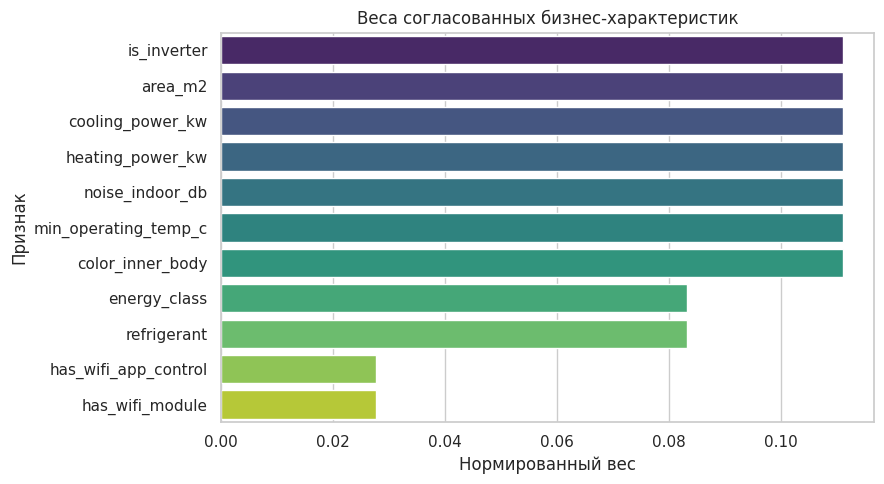

In [4]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=BUSINESS_WEIGHTS_DF,
    x="weight",
    y="field",
    hue="field",
    orient="h",
    palette="viridis",
    legend=False,
)
plt.title("Веса согласованных бизнес-характеристик")
plt.xlabel("Нормированный вес")
plt.ylabel("Признак")
plt.tight_layout()
plt.savefig(ARTIFACT_PATHS["visualizations"] / "business_weights.png", dpi=150)
plt.show()

In [5]:
class Characteristic(BaseModel):
    model_config = ConfigDict(extra="ignore", populate_by_name=True)
    name: Optional[str] = Field(default=None, alias="Name")
    value: Any = Field(default=None, alias="Value")

class AnalogEntry(BaseModel):
    model_config = ConfigDict(extra="ignore", populate_by_name=True)
    product_id: Optional[str] = Field(default=None, alias="ProductId")
    match_score: Optional[Any] = Field(default=None, alias="MatchScore")
    source: Optional[Any] = Field(default=None, alias="Source")
    def normalized_product_id(self) -> Optional[str]:
        if not self.product_id:
            return None
        return str(self.product_id).strip() or None

class ProductRecord(BaseModel):
    model_config = ConfigDict(extra="ignore", populate_by_name=True)
    id: Optional[str] = Field(default=None, alias="Id")
    name: Optional[str] = Field(default=None, alias="Name")
    code: Optional[str] = Field(default=None, alias="Code")
    characteristics: List[Characteristic] = Field(default_factory=list, alias="Characteristics")
    analogs: List[AnalogEntry] = Field(default_factory=list, alias="Analogs")
    def normalized_id(self) -> str:
        if self.id:
            return str(self.id).strip()
        raw_key = f"{self.name or ''}|{self.code or ''}"
        return f"fallback_{uuid.uuid5(uuid.NAMESPACE_DNS, raw_key)}"
    def get_analog_ids(self) -> List[str]:
        result = []
        for item in self.analogs:
            pid = item.normalized_product_id()
            if pid:
                result.append(pid)
        return result

def load_records_json(path: str, max_records: Optional[int] = None) -> List[Dict[str, Any]]:
    input_path = Path(path)
    if not input_path.exists():
        raise FileNotFoundError(f"Data file not found: {input_path}")
    file_size_mb = input_path.stat().st_size / 1e6
    LOGGER.info("Loading JSON file: %s (%.2f MB)", input_path, file_size_mb)
    records: List[Dict[str, Any]] = []
    with open(input_path, "r", encoding="utf-8") as f:
        first_char = f.read(1).strip()
        f.seek(0)
        if first_char == "[":
            raw = json.load(f)
            if not isinstance(raw, list):
                raise ValueError("Root JSON object must be a list of records.")
            records = raw
        else:
            for line_no, line in enumerate(f, start=1):
                line = line.strip()
                if not line:
                    continue
                try:
                    records.append(json.loads(line))
                except json.JSONDecodeError as exc:
                    LOGGER.warning("Failed to parse line %d: %s", line_no, exc)
    if max_records is not None:
        records = records[:max_records]
    LOGGER.info("Loaded records: %d", len(records))
    return records

In [6]:
raw_records = load_records_json(CONFIG.DATA_PATH, max_records=CONFIG.MAX_RECORDS)

2026-11-20 07:56:50 | INFO    | analog_v3 | Loading JSON file: data/raw/catalog_products.json (183.43 MB)
2026-11-20 07:56:52 | INFO    | analog_v3 | Loaded records: 8591


In [7]:
def normalize_text(value: Any) -> str:
    if value is None:
        return ""
    text = str(value)
    text = text.replace("\u00a0", " ")
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = text.replace("“", '"')
    text = text.replace("”", '"')
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

def parse_number(value: Any) -> Optional[float]:
    if value is None:
        return None
    if isinstance(value, bool):
        return None
    if isinstance(value, (int, float)):
        try:
            num = float(value)
            return None if math.isnan(num) else num
        except Exception:
            return None
    text = str(value)
    text = text.replace("\u00a0", " ")
    text = text.replace("−", "-")
    text = text.replace("–", "-")
    text = text.replace("—", "-")
    text = text.replace(",", ".")
    text = re.sub(r"(\d)\s+(?=\d)", r"\1", text)
    match = re.search(r"(-?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)", text)
    if not match:
        return None
    try:
        num = float(match.group(1))
        return None if math.isnan(num) else num
    except Exception:
        return None

    
def normalize_area_m2(raw: Any) -> Optional[float]:
    value = parse_number(raw)
    if value is None or value <= 0 or value > 2000:
        return None
    return float(value)

def normalize_power_kw(raw: Any) -> Optional[float]:
    value = parse_number(raw)
    if value is None or value <= 0:
        return None
    if value > 100:
        kw = value / W_TO_KW
    else:
        kw = value
    if kw <= 0 or kw > 250:
        return None
    return float(kw)

def normalize_noise_db(raw: Any) -> Optional[float]:
    value = parse_number(raw)
    if value is None or value <= 0 or value > 120:
        return None
    return float(value)

def normalize_temp_c(raw: Any) -> Optional[float]:
    value = parse_number(raw)
    if value is None or value < -80 or value > 80:
        return None
    return float(value)

NULLISH_TOKENS: Set[str] = {
    "",
    "nan",
    "none",
    "null",
    "-",
    "–",
    "—",
    "n/a",
    "na",
    "нет",
    "не указано",
    "не указан",
    "не заполнено",
    "unknown",
    "?",
    "false",
}
BOOL_TRUE_EXACT = {
    "true",
    "yes",
    "y",
    "1",
    "on",
    "enabled",
    "available",
    "included",
    "integrated",
    "built-in",
    "builtin",
    "onboard",
    "on board",
    "да",
    "есть",
    "да есть",
    "есть да",
    "имеется",
    "имеет",
    "наличие",
    "присутствует",
    "доступно",
    "доступен",
    "доступна",
    "доступно",
    "поддерживается",
    "поддерживает",
    "в наличии",
    "в комплекте",
    "в комплекте поставки",
    "в комплект",
    "встроен",
    "встроенный",
    "встроенная",
    "встроенное",
    "встроенном",
    "встроенной",
    "с функцией",
    "с модулем",
    "есть функция",
    "есть модуль",
}
BOOL_FALSE_EXACT = {
    "false",
    "no",
    "n",
    "0",
    "off",
    "disabled",
    "not available",
    "not included",
    "not supported",
    "missing",
    "absent",
    "off board",
    "offboard",
    "no wifi",
    "нет",
    "не",
    "отсутствует",
    "отсутств",
    "отсутствует",
    "не имеется",
    "не имеет",
    "не имеет функции",
    "не поддерживает",
    "не поддерживается",
    "недоступно",
    "недоступен",
    "недоступна",
    "недоступно",
    "не в наличии",
    "не в комплекте",
    "не входит в комплект",
    "не входит в комплект поставки",
    "без",
    "без модуля",
    "без функции",
    "нет модуля",
    "нет функции",
    "отключено",
    "отключена",
    "отключён",
    "отключено",
}
BOOL_NULLISH_EXACT = {
    "",
    "nan",
    "none",
    "null",
    "-",
    "–",
    "—",
    "n/a",
    "na",
    "нет данных",
    "нет информации",
    "не указано",
    "не указан",
    "не указана",
    "не указана",
    "не заполнено",
    "не заполнен",
    "неизвестно",
    "неизвестен",
    "неизвестна",
    "не известно",
    "уточнить",
    "уточняется",
    "уточнить у продавца",
    "подтверждается",
    "unknown",
    "tbd",
    "to be determined",
    "under review",
}
BOOL_TRUE_PHRASES = [
    "в наличии",
    "в комплекте",
    "в комплекте поставки",
    "поддерживается",
    "поддерживает",
    "доступен",
    "доступна",
    "доступно",
    "имеется",
    "присутствует",
    "встроен",
    "встроенный",
    "встроенная",
    "встроенное",
    "built-in",
    "builtin",
    "on board",
    "onboard",
    "при подключении",
    "с функцией",
    "с модулем",
    "есть функция",
    "есть модуль",
    "есть",
    "да",
]
BOOL_FALSE_PHRASES = [
    "не в наличии",
    "не в комплекте",
    "не входит в комплект",
    "не входит в комплект поставки",
    "не поддерживается",
    "не поддерживается",
    "не поддерживает",
    "не имеет",
    "не имеется",
    "недоступно",
    "недоступен",
    "недоступна",
    "недоступно",
    "отсутствует",
    "отсутств",
    "нет модуля",
    "нет функции",
    "без модуля",
    "без функции",
    "off",
    "off board",
    "offboard",
    "no wifi",
    "не",
    "нет",
]

W_TO_KW = 1000.0
COLOR_SYNONYM_GROUPS: Dict[str, List[str]] = {
    "Белый": [
        "белый",
        "бел",
        "white",
        "белоснежный",
        "белоснежно-белый",
        "белоснежный",
        "молочный",
        "молочно-белый",
        "молочный белый",
        "off white",
        "off-white",
        "бело-снежный",
        "bianco traffico",
        "ral 9016",
        "ral9016",
        "ral 016",
        "ral9016",
        "ral 9003",
        "ral9003",
        "ral 9010",
        "ral9010",
        "signal white",
    ],
    "Чёрный": [
        "черный",
        "чёрный",
        "black",
        "noir sable",
        "noir",
        "matte black",
        "матовый черный",
        "матовый чёрный",
        "черный матовый",
        "чёрный матовый",
        "ral 9005",
        "ral9005",
        "ral 9007",
        "ral9007",
        "jet black",
        "deep black",
    ],
    "Серебристый": [
        "серебристый",
        "silver",
        "silver satin",
        "серебро",
        "серебристый металлик",
        "серебристый металлик",
        "ss",
        "/ss",
        "\\ss",
        "ss",
        "aluminium",
        "алюминий",
        "алюминиевый",
        "ral 9006",
        "ral9006",
        "silver metallic",
    ],
    "Серый": [
        "серый",
        "gray",
        "grey",
        "серебряный",
        "стальной",
        "сталь",
        "стальной цвет",
        "steel",
        "graphite",
        "графит",
        "графитовый",
        "металлик",
        "metallic",
        "металлический",
        "metal",
        "ral 7035",
        "ral7035",
        "ral 7040",
        "ral7040",
        "light gray",
        "light grey",
        "dark gray",
        "dark grey",
    ],
    "Слоновая кость": [
        "слоновая кость",
        "ivory",
        "ivoire",
        "ivory white",
        "белоснежная кость",
        "ral 1015",
        "ral1015",
    ],
    "Антрацит": [
        "антрацит",
        "anthracite",
        "anthracite grey",
        "anthracite gray",
        "ral 7016",
        "ral7016",
    ],
    "Бежевый": [
        "бежевый",
        "beige",
        "беж",
        "кремовый",
        "cream",
        "крем",
        "sand",
        "песочный",
        "песочный цвет",
        "camel",
        "камель",
        "tan",
        "тэн",
    ],
    "Коричневый": [
        "коричневый",
        "brown",
        "коричневый",
        "какао",
        "cocoa",
        "chocolate",
        "шоколадный",
        "coffee",
        "кофейный",
    ],
    "Бронзовый": [
        "бронзовый",
        "bronze",
        "бронза",
        "bronze metallic",
        "бронзовый металлик",
    ],
    "Золотой": [
        "золотой",
        "gold",
        "золотистый",
        "golden",
        "gold metallic",
        "золотой металлик",
        "золоченый",
        "shiny gold",
    ],
    "Синий": [
        "синий",
        "blue",
    ],
    "Голубой": [
        "голубой",
        "light blue",
        "sky blue",
        "голубоватый",
    ],
    "Красный": [
        "красный",
        "red",
        "алый",
        "crimson",
    ],
    "Бордовый": [
        "бордовый",
        "burgundy",
        "wine",
        "вишнёвый",
        "cherry",
    ],
    "Зелёный": [
        "зелёный",
        "зеленый",
        "green",
        "салатовый",
        "lime",
        "лимонно-зелёный",
        "emerald",
        "изумрудный",
    ],
    "Оранжевый": [
        "оранжевый",
        "orange",
        "персиковый",
        "peach",
    ],
    "Розовый": [
        "розовый",
        "pink",
    ],
    "Фиолетовый": [
        "фиолетовый",
        "purple",
        "пурпурный",
        "violet",
    ],
    "Бирюзовый": [
        "бирюзовый",
        "turquoise",
        "aqua",
        "аqua",
    ],
    "Титан": [
        "титан",
        "титаниум",
        "titanium",
        "titan",
        "titan gray",
        "titan grey",
        "titan silver",
    ],
    "Чёрно-белый": [
        "чёрно-белый",
        "черно-белый",
        "чёрный и белый",
        "черный и белый",
        "бело-чёрный",
        "бело-черный",
        "белый и черный",
        "белый и чёрный",
        "black white",
        "white black",
        "black/white",
        "white/black",
    ],
}
COLOR_SYNONYMS: Dict[str, str] = {}
for canonical, values in COLOR_SYNONYM_GROUPS.items():
    for value in values:
        if value is None:
            continue
        key = normalize_text(value)
        if not key:
            continue
        COLOR_SYNONYMS[key] = canonical
COLOR_RAL_CODES: Dict[str, str] = {
    "9016": "Белый",
    "9003": "Белый",
    "9010": "Белый",
    "9005": "Чёрный",
    "9007": "Чёрный",
    "9006": "Серебристый",
    "7035": "Серый",
    "7040": "Серый",
    "1015": "Слоновая кость",
    "7016": "Антрацит",
}
REFRIGERANT_SYNONYMS: Dict[str, str] = {
    "r410a": "R410A",
    "r-410a": "R410A",
    "r 410a": "R410A",
    "r410": "R410A",
    "r-410": "R410A",
    "r 410": "R410A",
    "410a": "R410A",
    "410": "R410A",
    "hfc-410a": "R410A",
    "hfc410a": "R410A",
    "hfc 410a": "R410A",
    "r32": "R32",
    "r-32": "R32",
    "r 32": "R32",
    "32": "R32",
    "hfc-32": "R32",
    "hfc32": "R32",
    "r22": "R22",
    "r-22": "R22",
    "r 22": "R22",
    "22": "R22",
    "r407c": "R407C",
    "r-407c": "R407C",
    "r 407c": "R407C",
    "407c": "R407C",
    "hfc-407c": "R407C",
    "hfc407c": "R407C",
    "r134a": "R134A",
    "r-134a": "R134A",
    "r 134a": "R134A",
    "134a": "R134A",
    "r290": "R290",
    "r-290": "R290",
    "r 290": "R290",
    "290": "R290",
    "r1234yf": "R1234YF",
    "r-1234yf": "R1234YF",
    "r 1234yf": "R1234YF",
    "1234yf": "R1234YF",
}
ENERGY_CLASS_SYNONYMS: Dict[str, str] = {
    "a+++": "A+++",
    "a +++": "A+++",
    "a+++/a+++": "A+++",
    "a++": "A++",
    "a ++": "A++",
    "a++/a++": "A++",
    "a++/a": "A++",
    "a+/a++": "A++",
    "a+": "A+",
    "a +": "A+",
    "a+/a": "A+",
    "a/a+": "A+",
    "a": "A",
    "a/a": "A",
    "b": "B",
    "b/b": "B",
    "c": "C",
    "c/c": "C",
    "d": "D",
    "d/d": "D",
    "e": "E",
    "e/e": "E",
    "f": "F",
    "f/f": "F",
    "g": "G",
    "g/g": "G",
}
CHAR_ALIASES: Dict[str, List[str]] = {
    "is_inverter": [
        "инверторная технология",
    ],
    "area_m2": [
        "эффективен для помещ. площадью до",
        "площадь помещения до",
    ],
    "cooling_power_kw": [
        "номинальная производительность охлаждения",
        "макс. производительность охлаждения",
        "макс. производительность",
    ],
    "heating_power_kw": [
        "номинальная производительность обогрева",
        "макс. производительность обогрева",
    ],
    "noise_indoor_db": [
        "уровень шума внутр. блока",
        "уровень шума внутреннего блока",
    ],
    "min_operating_temp_c": [
        "мин. рабочая температура воздуха для внешнего блока",
        "мин. рабочая температура воздуха для наружного блока",
    ],
    "color_inner_body": [
        "цвет корпуса внутр. блока",
        "цвет корпуса внутреннего блока",
    ],
    "has_wifi_module": [
        "wi-fi модуль",
    ],
    "has_wifi_app_control": [
        "управление c мобильного приложения по wi-fi",
    ],
    "refrigerant": [
        "хладагент",
    ],
    "energy_class": [
        "класс энергоэффективности",
        "энергоэффективность",
    ],
}
NUMERIC_PARSERS: Dict[str, Any] = {
    "area_m2": normalize_area_m2,
    "cooling_power_kw": normalize_power_kw,
    "heating_power_kw": normalize_power_kw,
    "noise_indoor_db": normalize_noise_db,
    "min_operating_temp_c": normalize_temp_c,
}

EPS = 1e-8
WEIGHT_EPS = 1e-12
CRITICAL_IMPORTANCE = 3
ENERGY_CLASS_SCORE_MAP: Dict[str, float] = {
    "A+++": 4.0,
    "A++": 3.0,
    "A+": 2.0,
    "A": 1.0,
    "B": 0.0,
    "C": -1.0,
    "D": -2.0,
    "E": -3.0,
    "F": -4.0,
    "G": -5.0,
}
ENERGY_CLASS_MAP: Dict[str, float] = {
    k.lower(): v
    for k, v in ENERGY_CLASS_SCORE_MAP.items()
}

def is_nullish_value(value: Any) -> bool:
    if value is None:
        return True
    if isinstance(value, float) and math.isnan(value):
        return True
    if isinstance(value, str):
        token = normalize_text(value)
        if token in NULLISH_TOKENS:
            return True
        if not token:
            return True
    return False

def parse_bool_synonyms(value: Any) -> Optional[bool]:
    if value is None:
        return None
    if is_nullish_value(value):
        return None
    if isinstance(value, bool):
        return value
    if isinstance(value, (int, float)):
        try:
            num = float(value)
            if num == 1.0:
                return True
            if num == 0.0:
                return False
        except Exception:
            pass
    text = normalize_text(value)
    if not text:
        return None
    if text in BOOL_TRUE_EXACT:
        return True
    if text in BOOL_FALSE_EXACT:
        return False
    if text in BOOL_NULLISH_EXACT:
        return None
    for phrase in BOOL_FALSE_PHRASES:
        if phrase in text:
            return False
    for phrase in BOOL_TRUE_PHRASES:
        if phrase in text:
            return True
    return None

def parse_bool(value: Any) -> Optional[bool]:
    return parse_bool_synonyms(value)
    
def normalize_color_synonyms(value: Any) -> Optional[str]:
    if value is None:
        return None
    if is_nullish_value(value):
        return None
    text = normalize_text(value)
    if not text:
        return None
    if text in COLOR_SYNONYMS:
        return COLOR_SYNONYMS[text]
    ral_match = re.search(r"ral\s*([0-9]{4})", text)
    if ral_match:
        code = ral_match.group(1)
        if code in COLOR_RAL_CODES:
            return COLOR_RAL_CODES[code]
    found_canonicals = []
    sorted_keys = sorted(COLOR_SYNONYMS.keys(), key=len, reverse=True)
    for key in sorted_keys:
        if not key:
            continue
        if key in text:
            canonical = COLOR_SYNONYMS[key]
            if canonical == "Чёрно-белый":
                return canonical
            if canonical not in found_canonicals:
                found_canonicals.append(canonical)
    if not found_canonicals:
        tokens = [t for t in re.split(r"\s+", text) if t]
        for token in tokens:
            if token in COLOR_SYNONYMS:
                return COLOR_SYNONYMS[token]
        clean = re.sub(r"[^a-zа-яё0-9\s\-/]+", " ", text)
        clean = re.sub(r"\s+", " ", clean).strip()
        if not clean:
            return None
        return clean.title()
    if len(found_canonicals) == 1:
        return found_canonicals[0]
    return "Смешанный"

def normalize_color(value: Any) -> Optional[str]:
    return normalize_color_synonyms(value)

def normalize_refrigerant_synonyms(value: Any) -> Optional[str]:
    if value is None:
        return None
    if is_nullish_value(value):
        return None
    text = normalize_text(value)
    if not text:
        return None
    compact = re.sub(r"[\s\-]+", "", text)
    if compact in REFRIGERANT_SYNONYMS:
        return REFRIGERANT_SYNONYMS[compact]
    if text in REFRIGERANT_SYNONYMS:
        return REFRIGERANT_SYNONYMS[text]
    match = re.search(r"r[- ]?(\d+[a-z]?)", text)
    if match:
        candidate = "R" + match.group(1).upper()
        if candidate in {"R410", "R410A", "R410a"}:
            return "R410A"
        if candidate in REFRIGERANT_SYNONYMS.values():
            return candidate
    return text.upper()


def normalize_category(value: Any, max_length: int = 80) -> Optional[str]:
    if is_nullish_value(value):
        return None
    parsed_bool = parse_bool_synonyms(value)
    if parsed_bool is not None:
        return "true" if parsed_bool else "false"
    text = normalize_text(value)
    if not text or is_nullish_value(text):
        return None
    text = re.sub(r"\s+", " ", text).strip()
    if len(text) > max_length:
        text = text[:max_length].strip()
    return text or None

def normalize_energy_class_synonyms(value: Any) -> Optional[str]:
    if value is None:
        return None
    if is_nullish_value(value):
        return None
    text = normalize_text(value)
    if not text:
        return None
    if text in ENERGY_CLASS_SYNONYMS:
        return ENERGY_CLASS_SYNONYMS[text]
    compact = re.sub(r"\s+", "", text)
    if compact in ENERGY_CLASS_SYNONYMS:
        return ENERGY_CLASS_SYNONYMS[compact]
    match = re.search(r"([a-g])\s*(\+*)", text)
    if match:
        letter = match.group(1).upper()
        plus = match.group(2)
        return letter + plus
    return None

def normalize_energy_class(value: Any) -> Optional[str]:
    return normalize_energy_class_synonyms(value)

CATEGORICAL_PARSERS: Dict[str, Any] = {
    "color_inner_body": normalize_color,
    "refrigerant": normalize_category,
    "energy_class": normalize_energy_class,
    "has_wifi_module": parse_bool,
    "has_wifi_app_control": parse_bool,
    "is_inverter": parse_bool,
}
    
def build_characteristic_map(product: ProductRecord) -> Dict[str, Any]:
    char_map: Dict[str, Any] = {}
    for ch in product.characteristics:
        if not ch.name:
            continue
        norm_name = normalize_text(ch.name)
        if not norm_name:
            continue
        if ch.value is None:
            continue
        if norm_name not in char_map:
            char_map[norm_name] = ch.value
    return char_map

def first_non_null_by_aliases(
    char_map: Dict[str, Any],
    aliases: List[str],
) -> Optional[Any]:
    for alias in aliases:
        value = char_map.get(normalize_text(alias))
        if not is_nullish_value(value):
            return value
    return None

def build_product_profile(product: ProductRecord) -> Dict[str, Any]:
    char_map = build_characteristic_map(product)
    profile = {
        "id": product.normalized_id(),
        "name": product.name,
        "normalized_name": normalize_text(product.name),
        "code": product.code,
        "analogs": product.get_analog_ids(),
    }
    for field_name, aliases in CHAR_ALIASES.items():
        raw_value = first_non_null_by_aliases(char_map, aliases)
        if field_name == "color_inner_body":
            profile[field_name] = normalize_color(raw_value)
        elif field_name in {"is_inverter", "has_wifi_module", "has_wifi_app_control"}:
            profile[field_name] = parse_bool(raw_value)
        elif field_name == "refrigerant":
            profile[field_name] = normalize_refrigerant_synonyms(raw_value)
        elif field_name == "energy_class":
            profile[field_name] = normalize_energy_class(raw_value)
        else:
            parser = NUMERIC_PARSERS.get(field_name)
            profile[field_name] = parser(raw_value) if parser else None
    return profile

def is_empty_value(value: Any) -> bool:
    if value is None:
        return True
    if isinstance(value, bool):
        return False
    if isinstance(value, (list, dict, set, frozenset)):
        return len(value) == 0
    if isinstance(value, str):
        return is_nullish_value(value)
    try:
        return math.isnan(float(value))
    except Exception:
        return False

def unique_str_list(items: Iterable[Any]) -> List[str]:
    result = []
    seen = set()
    for item in items or []:
        s = str(item).strip()
        if s and s not in seen:
            result.append(s)
            seen.add(s)
    return result

def normalize_analog_ids(analog_ids: Iterable[Any], self_id: str) -> List[str]:
    result = []
    seen = set()
    for analog_id in analog_ids or []:
        pid = str(analog_id).strip()
        if not pid:
            continue
        if pid == self_id:
            continue
        if pid not in seen:
            result.append(pid)
            seen.add(pid)
    return result

def merge_duplicate_profiles(profiles: Iterable[Dict[str, Any]]) -> List[Dict[str, Any]]:
    merged: Dict[str, Dict[str, Any]] = {}
    for raw_profile in profiles:
        profile = dict(raw_profile)
        product_id = str(profile.get("id", "")).strip()
        if not product_id:
            continue
        profile["analogs"] = normalize_analog_ids(profile.get("analogs", []), product_id)
        if product_id not in merged:
            item = dict(profile)
            name_variants = []
            normalized_variants = []
            if not is_empty_value(item.get("name")):
                name_variants.append(str(item.get("name")).strip())
            if not is_empty_value(item.get("normalized_name")):
                normalized_variants.append(str(item.get("normalized_name")).strip().lower())
            item["name_variants"] = unique_str_list(name_variants)
            item["normalized_name_variants"] = unique_str_list(
                [normalize_text(x) for x in item["name_variants"]]
            )
            item["name_haystack"] = " ".join(
                unique_str_list(item["name_variants"] + item["normalized_name_variants"])
            ).lower()
            item["_merge_conflicts"] = []
            merged[product_id] = item
            continue
        target = merged[product_id]
        existing_analogs = normalize_analog_ids(target.get("analogs", []), product_id)
        seen_analogs = set(existing_analogs)
        for analog_id in profile.get("analogs", []):
            analog_id = str(analog_id).strip()
            if not analog_id or analog_id == product_id:
                continue
            if analog_id not in seen_analogs:
                existing_analogs.append(analog_id)
                seen_analogs.add(analog_id)
        target["analogs"] = existing_analogs
        incoming_names = []
        if not is_empty_value(profile.get("name")):
            incoming_names.append(str(profile.get("name")).strip())
        if not is_empty_value(profile.get("normalized_name")):
            incoming_names.append(str(profile.get("normalized_name")).strip())
        target["name_variants"] = unique_str_list(
            target.get("name_variants", []) + incoming_names
        )
        target["normalized_name_variants"] = unique_str_list(
            [normalize_text(x) for x in target.get("name_variants", [])]
        )
        target["name_haystack"] = " ".join(
            unique_str_list(target.get("normalized_name_variants", []))
        ).lower()
        if is_empty_value(target.get("name")):
            target["name"] = profile.get("name")

        if is_empty_value(target.get("normalized_name")):
            target["normalized_name"] = profile.get("normalized_name")
        skip_fields = {
            "id",
            "name",
            "normalized_name",
            "name_variants",
            "normalized_name_variants",
            "name_haystack",
            "analogs",
            "_merge_conflicts",
        }
        for field_name, incoming_value in profile.items():
            if field_name in skip_fields:
                continue
            existing_value = target.get(field_name)
            if is_empty_value(existing_value):
                target[field_name] = incoming_value
            else:
                if isinstance(existing_value, float) and isinstance(incoming_value, float):
                    close = abs(existing_value - incoming_value) < 1e-6
                    if not close:
                        target["_merge_conflicts"].append({
                            "field": field_name,
                            "kept": existing_value,
                            "incoming": incoming_value,
                        })
                else:
                    if str(existing_value).lower() != str(incoming_value).lower():
                        target["_merge_conflicts"].append({
                            "field": field_name,
                            "kept": existing_value,
                            "incoming": incoming_value,
                        })
    return list(merged.values())

def build_profiles_from_records(records: Iterable[Dict[str, Any]]) -> pd.DataFrame:
    raw_profiles = []
    validation_errors = 0
    for idx, record in enumerate(records):
        try:
            product = ProductRecord.model_validate(record)
            profile = build_product_profile(product)
            raw_profiles.append(profile)
        except ValidationError as exc:
            validation_errors += 1
            if validation_errors <= 20:
                LOGGER.warning("Validation error on record %d: %s", idx, exc)
        except Exception as exc:
            validation_errors += 1
            if validation_errors <= 20:
                LOGGER.warning("Unexpected error on record %d: %s", idx, exc)
    merged_profiles = merge_duplicate_profiles(raw_profiles)
    df = pd.DataFrame(merged_profiles)
    LOGGER.info(
        "Profiles built: raw=%d, merged_unique_id=%d, validation_errors=%d",
        len(raw_profiles),
        len(df),
        validation_errors,
    )
    return df

def is_valid_number(value: Any) -> bool:
    if value is None:
        return False
    try:
        num = float(value)
        return not math.isnan(num)
    except Exception:
        return False

def relative_abs_difference(a: Optional[float], b: Optional[float]) -> Optional[float]:
    if not is_valid_number(a) or not is_valid_number(b):
        return None
    a = float(a)
    b = float(b)
    denominator = (abs(a) + abs(b)) / 2.0
    if denominator < EPS:
        denominator = EPS
    return abs(a - b) / denominator

def absolute_difference(a: Optional[float], b: Optional[float]) -> Optional[float]:
    if not is_valid_number(a) or not is_valid_number(b):
        return None
    return abs(float(a) - float(b))

def compare_numeric_relative(
    query_value: Any,
    candidate_value: Any,
    tolerance_percent: Optional[float],
    importance: int = 0,
) -> Tuple[float, bool]:
    if not is_valid_number(query_value) or not is_valid_number(candidate_value):
        return 0.5, False
    q = float(query_value)
    c = float(candidate_value)
    diff = absolute_difference(q, c)
    if diff is None:
        return 0.5, False
    reference = max(abs(q), 1.0)
    if tolerance_percent is None:
        allowed = 0.0
    else:
        allowed = reference * float(tolerance_percent) / 100.0
    if diff <= allowed:
        return 1.0, False
    score = max(0.0, 1.0 - (diff - allowed) / max(allowed, reference * 0.2, EPS))
    return score, False

def compare_temp_relative(query_value: Any, candidate_value: Any, tolerance_percent: Optional[float]) -> Tuple[float, bool]:
    if not is_valid_number(query_value) or not is_valid_number(candidate_value):
        return 0.5, False
    q = float(query_value)
    c = float(candidate_value)
    diff = absolute_difference(q, c)
    if diff is None:
        return 0.5, False
    reference = max(abs(q), 1.0)
    if tolerance_percent is None:
        allowed = 0.0
    else:
        allowed = reference * float(tolerance_percent) / 100.0
    if diff <= allowed:
        return 1.0, False
    hard_fail = True
    return 0.0, hard_fail

def compare_bool(
    query_value: Any,
    candidate_value: Any,
    importance: int,
) -> Tuple[float, bool]:
    q_valid = not is_nullish_value(query_value)
    c_valid = not is_nullish_value(candidate_value)
    if not q_valid or not c_valid:
        return 0.5, False
    q = query_value is True
    c = candidate_value is True
    if q == c:
        return 1.0, False
    hard_fail = importance >= CRITICAL_IMPORTANCE
    return 0.0, hard_fail

def compare_category_exact(
    query_value: Any,
    candidate_value: Any,
    importance: int,
) -> Tuple[float, bool]:
    q_valid = not is_nullish_value(query_value)
    c_valid = not is_nullish_value(candidate_value)
    if not q_valid or not c_valid:
        return 0.5, False
    q = str(query_value).strip().lower()
    c = str(candidate_value).strip().lower()
    if q == c:
        return 1.0, False
    hard_fail = importance >= CRITICAL_IMPORTANCE
    return 0.0, hard_fail

def normalize_energy_class_safe(value: Any) -> Optional[str]:
    if value is None:
        return None
    if is_nullish_value(value):
        return None
    if "normalize_energy_class_synonyms" in globals():
        try:
            normalized = normalize_energy_class_synonyms(value)
            if normalized:
                return normalized
        except Exception:
            pass
    text = normalize_text(value)
    if not text:
        return None
    compact = re.sub(r"[^a-z+]", "", text)
    if not compact:
        return None
    matches = re.findall(r"([a-g])(\+*)", compact)
    if not matches:
        return None
    letter, plus = matches[0]
    return letter.upper() + plus


def energy_class_to_score(value: Any) -> Optional[float]:
    canonical = normalize_energy_class_safe(value)
    if canonical is None:
        return None
    canonical = canonical.upper()
    if canonical not in ENERGY_CLASS_SCORE_MAP:
        match = re.fullmatch(r"([A-G])(\+{0,3})", canonical)
        if not match:
            return None
        canonical = match.group(1) + match.group(2)
    return ENERGY_CLASS_SCORE_MAP.get(canonical)

def compare_energy_class(query_value: Any, candidate_value: Any) -> Tuple[float, bool]:
    q_score = energy_class_to_score(query_value)
    c_score = energy_class_to_score(candidate_value)
    if q_score is None or c_score is None:
        return 0.5, False
    if c_score >= q_score:
        return 1.0, False
    diff = q_score - c_score
    score = max(0.0, 1.0 - diff / 4.0)
    return score, False

def is_present_for_field(
    kind: str,
    query_value: Any,
    candidate_value: Any,
) -> bool:
    if kind in {"numeric_relative", "temp_relative"}:
        return is_valid_number(query_value) and is_valid_number(candidate_value)
    return not is_nullish_value(query_value) and not is_nullish_value(candidate_value)

def business_pair_score(
    query_row: pd.Series,
    candidate_row: pd.Series,
) -> Dict[str, Any]:
    total_weight = 0.0
    valid_weight = 0.0
    weighted_sum = 0.0
    hard_fail = False
    active_fields: List[str] = []
    valid_fields: List[str] = []
    missing_fields: List[str] = []
    hard_fail_fields: List[str] = []
    details: Dict[str, Dict[str, Any]] = {}
    for item in BUSINESS_CHARACTERISTICS_CLEAN:
        field = item["Field"]
        kind = item["Kind"]
        importance = item["Importance"]
        tolerance = item["TolerancePercent"]
        weight = BUSINESS_WEIGHTS.get(field, 0.0)
        if weight <= WEIGHT_EPS:
            details[field] = {
                "component_score": None,
                "weight": 0.0,
                "hard_fail": False,
                "skipped": True,
                "missing": None,
                "reason": "zero_weight",
            }
            continue
        qv = query_row.get(field)
        cv = candidate_row.get(field)
        present = is_present_for_field(kind, qv, cv)
        if not present:
            component_score, fail = 0.5, False
            missing = True
        else:
            missing = False
            if kind == "numeric_relative":
                component_score, fail = compare_numeric_relative(
                    qv, cv, tolerance, importance
                )
            elif kind == "temp_relative":
                component_score, fail = compare_temp_relative(
                    qv, cv, tolerance
                )
            elif kind == "bool":
                component_score, fail = compare_bool(
                    qv, cv, importance
                )
            elif kind == "category_exact":
                component_score, fail = compare_category_exact(
                    qv, cv, importance
                )
            elif kind == "category_soft":
                component_score, fail = compare_category_soft(
                    qv, cv, importance
                )
            elif kind == "energy_class":
                component_score, fail = compare_energy_class(
                    qv, cv
                )
            else:
                component_score, fail = 0.5, False
        if fail and importance < CRITICAL_IMPORTANCE:
            fail = False
        total_weight += weight
        active_fields.append(field)
        if fail:
            hard_fail = True
            hard_fail_fields.append(field)
        if missing:
            missing_fields.append(field)
        else:
            valid_fields.append(field)
            valid_weight += weight
            weighted_sum += weight * component_score
        details[field] = {
            "component_score": float(component_score),
            "weight": float(weight),
            "hard_fail": bool(fail),
            "skipped": False,
            "missing": bool(missing),
        }
    if total_weight <= WEIGHT_EPS:
        return {
            "score": 0.5,
            "valid_score": None,
            "total_weight": 0.0,
            "valid_weight": 0.0,
            "confidence": 0.0,
            "hard_fail": False,
            "status": "no_business_features",
            "reason": "no_business_features",
            "active_fields": active_fields,
            "valid_fields": valid_fields,
            "missing_fields": missing_fields,
            "hard_fail_fields": hard_fail_fields,
            "component_details": details,
        }
    confidence = valid_weight / total_weight
    if valid_weight > 0:
        score = weighted_sum / total_weight
        valid_score = weighted_sum / valid_weight
    else:
        score = 0.5
        valid_score = None
    if valid_weight <= WEIGHT_EPS:
        status = "no_valid_feature_data"
        reason = "no_feature_value_present_for_both_products"
    else:
        status = "ok"
        reason = None
    valid_field_count = len(valid_fields)
    core_valid_field_count = len(
        [
            f
            for f in valid_fields
            if f in CORE_TECHNICAL_FIELDS
        ]
    )
    return {
        "score": float(score),
        "valid_score": float(valid_score) if valid_score is not None else None,
        "total_weight": float(total_weight),
        "valid_weight": float(valid_weight),
        "confidence": float(confidence),
        "hard_fail": bool(hard_fail),
        "status": status,
        "reason": reason,
        "active_fields": active_fields,
        "valid_fields": valid_fields,
        "missing_fields": missing_fields,
        "hard_fail_fields": hard_fail_fields,
        "component_details": details,
        "valid_field_count": int(valid_field_count),
        "core_valid_field_count": int(core_valid_field_count),
    }

CORE_TECHNICAL_FIELDS: Set[str] = {
    "cooling_power_kw",
    "area_m2",
    "heating_power_kw",
}

def compute_pair_validity(
    query_row: pd.Series,
    candidate_row: pd.Series,
) -> Dict[str, Any]:
    valid_fields: List[str] = []
    missing_fields: List[str] = []
    core_valid_fields: List[str] = []
    core_available_fields: List[str] = []
    total_weight = 0.0
    valid_weight = 0.0
    core_available_weight = 0.0
    core_valid_weight = 0.0
    for item in BUSINESS_CHARACTERISTICS_CLEAN:
        field = item["Field"]
        kind = item["Kind"]
        weight = BUSINESS_WEIGHTS.get(field, 0.0)
        if weight <= WEIGHT_EPS:
            continue
        qv = query_row.get(field)
        cv = candidate_row.get(field)
        present = is_present_for_field(kind, qv, cv)
        total_weight += weight
        if field in CORE_TECHNICAL_FIELDS:
            core_available_fields.append(field)
            core_available_weight += weight
        if present:
            valid_fields.append(field)
            valid_weight += weight
            if field in CORE_TECHNICAL_FIELDS:
                core_valid_fields.append(field)
                core_valid_weight += weight
        else:
            missing_fields.append(field)
    confidence = valid_weight / total_weight if total_weight > 0 else 0.0
    core_confidence = (
        core_valid_weight / core_available_weight
        if core_available_weight > 0
        else 0.0
    )
    required_core_count = (
        min(2, len(core_available_fields))
        if core_available_fields
        else 0
    )
    is_evaluable = (
        len(valid_fields) >= 2
        and len(core_valid_fields) >= required_core_count
    )
    if is_evaluable:
        reason = None
    else:
        reason = "insufficient_technical_data"
    return {
        "is_evaluable": bool(is_evaluable),
        "reason": reason,
        "valid_fields": valid_fields,
        "missing_fields": missing_fields,
        "core_valid_fields": core_valid_fields,
        "valid_field_count": len(valid_fields),
        "core_valid_field_count": len(core_valid_fields),
        "core_required_field_count": int(required_core_count),
        "total_weight": float(total_weight),
        "valid_weight": float(valid_weight),
        "confidence": float(confidence),
        "core_confidence": float(core_confidence),
    }

def collect_business_score_distribution(
    df: pd.DataFrame,
    ground_truth: Dict[str, Set[str]],
    max_pairs: Optional[int] = None,
) -> pd.DataFrame:
    df_indexed = df.set_index("id", drop=False)
    rows = []
    pair_count = 0
    for query_id, analog_ids in ground_truth.items():
        if query_id not in df_indexed.index:
            continue
        query_row = df_indexed.loc[query_id]
        if isinstance(query_row, pd.DataFrame):
            query_row = query_row.iloc[0]
        for analog_id in analog_ids:
            if analog_id not in df_indexed.index:
                continue
            candidate_row = df_indexed.loc[analog_id]
            if isinstance(candidate_row, pd.DataFrame):
                candidate_row = candidate_row.iloc[0]
            scoring = business_pair_score(query_row, candidate_row)
            details = scoring.get("component_details", {})
            non_skipped_components = {
                field: detail
                for field, detail in details.items()
                if detail.get("skipped") is False
            }
            rows.append(
                {
                    "query_id": query_id,
                    "analog_id": analog_id,
                    "score": scoring.get("score"),
                    "status": scoring.get("status"),
                    "hard_fail": scoring.get("hard_fail"),
                    "total_weight": scoring.get("total_weight"),
                    "active_fields": "|".join(scoring.get("active_fields", [])),
                    "hard_fail_fields": "|".join(scoring.get("hard_fail_fields", [])),
                    "missing_fields": "|".join(scoring.get("missing_fields", [])),
                    "component_count": len(non_skipped_components),
                }
            )
            pair_count += 1
            if max_pairs is not None and pair_count >= max_pairs:
                return pd.DataFrame(rows)
    return pd.DataFrame(rows)

def raw_ids_from_records(records: List[Dict[str, Any]]) -> pd.Series:
    ids = []
    for record in records:
        raw_id = record.get("Id", record.get("id", ""))
        raw_id = str(raw_id).strip()
        ids.append(raw_id)
    return pd.Series(ids, name="id")

def raw_record_has_analogs(record: Dict[str, Any]) -> bool:
    analogs = record.get("Analogs", record.get("analogs", []))
    if not isinstance(analogs, list):
        return False
    for item in analogs:
        if isinstance(item, dict):
            pid = item.get("ProductId", item.get("Id", item.get("id", "")))
        else:
            pid = item
        pid = str(pid).strip()
        if pid:
            return True
    return False

def raw_analog_ids_for_record(record: Dict[str, Any]) -> List[str]:
    analogs = record.get("Analogs", record.get("analogs", []))
    result = []
    if isinstance(analogs, list):
        for item in analogs:
            if isinstance(item, dict):
                pid = item.get("ProductId", item.get("Id", item.get("id", "")))
            else:
                pid = item
            pid = str(pid).strip()
            if pid:
                result.append(pid)
    return result

def diagnose_raw_analogs(records: List[Dict[str, Any]]) -> Dict[str, Any]:
    raw_ids = raw_ids_from_records(records)
    total_rows = len(records)
    empty_id_rows = int((raw_ids == "").sum())
    unique_non_empty_ids = int(raw_ids[raw_ids != ""].nunique())
    rows_with_analogs = sum(1 for r in records if raw_record_has_analogs(r))
    tmp = pd.DataFrame({
        "id": raw_ids,
        "has_analogs": [raw_record_has_analogs(r) for r in records],
    })
    ids_with_any_analog = int(
        tmp.loc[(tmp["id"] != "") & (tmp["has_analogs"]), "id"].nunique()
    )
    non_empty = raw_ids[raw_ids != ""].to_frame("id")
    duplicated_ids = non_empty.loc[non_empty["id"].duplicated(keep=False), "id"]
    duplicated_id_count = int(duplicated_ids.nunique())
    conflict_duplicated_ids = set()
    for pid, group in tmp[tmp["id"] != ""].groupby("id"):
        if len(group) > 1 and group["has_analogs"].any() and not group["has_analogs"].all():
            conflict_duplicated_ids.add(pid)
    all_analog_targets = []
    for record in records:
        all_analog_targets.extend(raw_analog_ids_for_record(record))
    return {
        "total_rows": total_rows,
        "empty_id_rows": empty_id_rows,
        "unique_non_empty_ids": unique_non_empty_ids,
        "rows_with_analogs": rows_with_analogs,
        "unique_ids_with_any_analog": ids_with_any_analog,
        "duplicated_id_count": duplicated_id_count,
        "conflict_duplicated_id_count": len(conflict_duplicated_ids),
        "conflict_duplicated_id_sample": sorted(list(conflict_duplicated_ids))[:20],
        "raw_analog_references_count": len(all_analog_targets),
        "unique_raw_analog_targets": len(set(all_analog_targets)),
    }

def build_analog_ground_truth(df: pd.DataFrame) -> Dict[str, Set[str]]:
    valid_ids = set(df["id"].astype(str).tolist())
    ground_truth: Dict[str, Set[str]] = {}
    for row in df.itertuples(index=False):
        query_id = str(row.id)
        raw_analogs = row.analogs if hasattr(row, "analogs") else []
        analog_ids = set()
        for analog_id in raw_analogs:
            analog_id = str(analog_id).strip()
            if not analog_id:
                continue
            if analog_id == query_id:
                continue
            if analog_id not in valid_ids:
                continue
            analog_ids.add(analog_id)
        if analog_ids:
            ground_truth[query_id] = analog_ids
    return ground_truth

def validate_analogs_with_business_rules(
    df: pd.DataFrame,
    ground_truth: Dict[str, Set[str]],
    threshold: float = 0.60,
    min_confidence: float = 0.50,
) -> Dict[str, Any]:
    df_indexed = df.set_index("id", drop=False)
    total_checked = 0
    passed = 0
    failed_hard_fail = 0
    failed_score = 0
    failed_no_valid_feature_data = 0
    failed_low_confidence = 0
    hard_fail_field_counts: Dict[str, int] = {}
    failed_examples: List[Dict[str, Any]] = []
    confidence_values = []
    score_values = []
    for query_id, analog_ids in ground_truth.items():
        if query_id not in df_indexed.index:
            continue
        query_row = df_indexed.loc[query_id]
        if isinstance(query_row, pd.DataFrame):
            query_row = query_row.iloc[0]
        for analog_id in analog_ids:
            if analog_id not in df_indexed.index:
                continue
            candidate_row = df_indexed.loc[analog_id]
            if isinstance(candidate_row, pd.DataFrame):
                candidate_row = candidate_row.iloc[0]
            scoring = business_pair_score(query_row, candidate_row)
            total_checked += 1
            confidence = float(scoring.get("confidence", 0.0))
            score = float(scoring.get("score", 0.0))
            status = scoring.get("status")
            confidence_values.append(confidence)
            score_values.append(score)
            if status in {"no_business_features", "no_valid_feature_data"}:
                failed_no_valid_feature_data += 1
                failed_examples.append(
                    {
                        "query_id": query_id,
                        "analog_id": analog_id,
                        "failure_type": "insufficient_data",
                        "status": status,
                        "reason": scoring.get("reason"),
                        "score": score,
                        "confidence": confidence,
                        "missing_fields": scoring.get("missing_fields", []),
                    }
                )
                continue
            if confidence < min_confidence:
                failed_low_confidence += 1
                failed_examples.append(
                    {
                        "query_id": query_id,
                        "analog_id": analog_id,
                        "failure_type": "low_confidence",
                        "score": score,
                        "confidence": confidence,
                        "missing_fields": scoring.get("missing_fields", []),
                    }
                )
                continue
            if scoring.get("hard_fail"):
                failed_hard_fail += 1
                for field in scoring.get("hard_fail_fields", []):
                    hard_fail_field_counts[field] = (
                        hard_fail_field_counts.get(field, 0) + 1
                    )
                failed_examples.append(
                    {
                        "query_id": query_id,
                        "analog_id": analog_id,
                        "failure_type": "hard_fail",
                        "hard_fail_fields": scoring.get("hard_fail_fields", []),
                        "score": score,
                        "confidence": confidence,
                    }
                )
                continue
            if score >= threshold:
                passed += 1
            else:
                failed_score += 1
                failed_examples.append(
                    {
                        "query_id": query_id,
                        "analog_id": analog_id,
                        "failure_type": "score_below_threshold",
                        "score": score,
                        "confidence": confidence,
                        "missing_fields": scoring.get("missing_fields", []),
                    }
                )
    pass_rate = passed / max(total_checked, 1)
    evaluable_total = (
        total_checked
        - failed_no_valid_feature_data
        - failed_low_confidence
    )
    pass_rate_evaluable = passed / max(evaluable_total, 1)
    return {
        "threshold": float(threshold),
        "min_confidence": float(min_confidence),
        "total_checked": int(total_checked),
        "passed": int(passed),
        "failed": int(total_checked - passed),
        "failed_hard_fail": int(failed_hard_fail),
        "failed_score": int(failed_score),
        "failed_no_valid_feature_data": int(failed_no_valid_feature_data),
        "failed_low_confidence": int(failed_low_confidence),
        "evaluable_total": int(evaluable_total),
        "evaluable_rate": float(evaluable_total / max(total_checked, 1)),
        "pass_rate": float(pass_rate),
        "pass_rate_evaluable": float(pass_rate_evaluable),
        "mean_score": float(np.mean(score_values)) if score_values else 0.0,
        "mean_confidence": float(np.mean(confidence_values)) if confidence_values else 0.0,
        "hard_fail_field_counts": hard_fail_field_counts,
        "failed_examples": failed_examples[:30],
    }

def build_evaluable_ground_truth(
    df: pd.DataFrame,
    ground_truth: Dict[str, Set[str]],
) -> Dict[str, Any]:
    df_indexed = df.set_index("id", drop=False)
    evaluable_ground_truth: Dict[str, Set[str]] = {}
    total_pairs = 0
    evaluable_pairs = 0
    uncheckable_pairs = 0
    examples_uncheckable: List[Dict[str, Any]] = []
    examples_evaluable: List[Dict[str, Any]] = []
    for query_id, analog_ids in ground_truth.items():
        if query_id not in df_indexed.index:
            continue
        query_row = df_indexed.loc[query_id]
        if isinstance(query_row, pd.DataFrame):
            query_row = query_row.iloc[0]
        valid_analogs: Set[str] = set()
        for analog_id in analog_ids:
            if analog_id not in df_indexed.index:
                continue
            candidate_row = df_indexed.loc[analog_id]
            if isinstance(candidate_row, pd.DataFrame):
                candidate_row = candidate_row.iloc[0]
            validity = compute_pair_validity(query_row, candidate_row)
            total_pairs += 1
            if validity["is_evaluable"]:
                evaluable_pairs += 1
                valid_analogs.add(analog_id)
                if len(examples_evaluable) < 10:
                    examples_evaluable.append(
                        {
                            "query_id": query_id,
                            "analog_id": analog_id,
                            "valid_fields": validity["valid_fields"],
                            "core_valid_fields": validity["core_valid_fields"],
                            "confidence": validity["confidence"],
                        }
                    )
            else:
                uncheckable_pairs += 1

                if len(examples_uncheckable) < 20:
                    examples_uncheckable.append(
                        {
                            "query_id": query_id,
                            "analog_id": analog_id,
                            "valid_fields": validity["valid_fields"],
                            "missing_fields": validity["missing_fields"],
                            "confidence": validity["confidence"],
                        }
                    )
        if valid_analogs:
            evaluable_ground_truth[query_id] = valid_analogs
    stats = {
        "total_pairs": int(total_pairs),
        "evaluable_pairs": int(evaluable_pairs),
        "uncheckable_pairs": int(uncheckable_pairs),
        "evaluable_rate": float(evaluable_pairs / max(total_pairs, 1)),
        "queries_total": int(len(ground_truth)),
        "queries_with_evaluable_analogs": int(len(evaluable_ground_truth)),
        "examples_uncheckable": examples_uncheckable,
        "examples_evaluable": examples_evaluable,
    }
    return {
        "evaluable_ground_truth": evaluable_ground_truth,
        "stats": stats,
    }

def export_failed_evaluable_pairs(
    df: pd.DataFrame,
    ground_truth: Dict[str, Set[str]],
    threshold: float = 0.60,
    limit: int = 100,
) -> pd.DataFrame:
    df_indexed = df.set_index("id", drop=False)
    rows = []
    for query_id, analog_ids in ground_truth.items():
        if query_id not in df_indexed.index:
            continue
        query_row = df_indexed.loc[query_id]
        if isinstance(query_row, pd.DataFrame):
            query_row = query_row.iloc[0]
        for analog_id in analog_ids:
            if analog_id not in df_indexed.index:
                continue
            candidate_row = df_indexed.loc[analog_id]
            if isinstance(candidate_row, pd.DataFrame):
                candidate_row = candidate_row.iloc[0]
            validity = compute_pair_validity(query_row, candidate_row)
            if not validity["is_evaluable"]:
                continue
            scoring = business_pair_score(query_row, candidate_row)
            if scoring["score"] >= threshold and not scoring["hard_fail"]:
                continue
            rows.append(
                {
                    "query_id": query_id,
                    "query_name": query_row.get("name"),
                    "analog_id": analog_id,
                    "analog_name": candidate_row.get("name"),
                    "score": scoring["score"],
                    "hard_fail": scoring["hard_fail"],
                    "hard_fail_fields": "|".join(scoring.get("hard_fail_fields", [])),
                    "valid_fields": "|".join(validity["valid_fields"]),
                    "core_valid_fields": "|".join(validity["core_valid_fields"]),
                    "confidence": validity["confidence"],
                }
            )
            if len(rows) >= limit:
                return pd.DataFrame(rows)
    return pd.DataFrame(rows)

def compute_analogs_source_quality(
    df: pd.DataFrame,
    ground_truth: Dict[str, Set[str]],
    threshold: float = 0.60,
) -> Dict[str, Any]:
    evaluable_source = build_evaluable_ground_truth(df, ground_truth)
    evaluable_ground_truth = evaluable_source["evaluable_ground_truth"]
    evaluable_stats = evaluable_source["stats"]
    all_pairs_validation = validate_analogs_with_business_rules(
        df=df,
        ground_truth=ground_truth,
        threshold=threshold,
        min_confidence=0.0,
    )
    evaluable_pairs_validation = validate_analogs_with_business_rules(
        df=df,
        ground_truth=evaluable_ground_truth,
        threshold=threshold,
        min_confidence=0.0,
    )
    total_pairs = evaluable_stats["total_pairs"]
    evaluable_pairs = evaluable_stats["evaluable_pairs"]
    uncheckable_pairs = evaluable_stats["uncheckable_pairs"]
    passed_all = all_pairs_validation["passed"]
    passed_evaluable = evaluable_pairs_validation["passed"]
    metrics = {
        "threshold": float(threshold),
        "total_pairs": int(total_pairs),
        "evaluable_pairs": int(evaluable_pairs),
        "uncheckable_pairs": int(uncheckable_pairs),
        "evaluable_rate": float(evaluable_pairs / max(total_pairs, 1)),
        "uncheckable_rate": float(uncheckable_pairs / max(total_pairs, 1)),
        "passed_all": int(passed_all),
        "pass_rate_all": float(passed_all / max(total_pairs, 1)),
        "passed_evaluable": int(passed_evaluable),
        "pass_rate_evaluable": float(passed_evaluable / max(evaluable_pairs, 1)),
        "failed_score_all": int(all_pairs_validation["failed_score"]),
        "failed_hard_fail_all": int(all_pairs_validation["failed_hard_fail"]),
        "failed_no_valid_feature_data_all": int(all_pairs_validation["failed_no_valid_feature_data"]),
        "failed_score_evaluable": int(evaluable_pairs_validation["failed_score"]),
        "failed_hard_fail_evaluable": int(evaluable_pairs_validation["failed_hard_fail"]),
        "mean_score_evaluable": float(evaluable_pairs_validation["mean_score"]),
        "mean_confidence_evaluable": float(evaluable_pairs_validation["mean_confidence"]),
    }
    return {
        "source_quality_metrics": metrics,
        "evaluable_ground_truth": evaluable_ground_truth,
        "all_pairs_validation": {
            k: v for k, v in all_pairs_validation.items()
            if k != "failed_examples"
        },
        "evaluable_pairs_validation": {
            k: v for k, v in evaluable_pairs_validation.items()
            if k != "failed_examples"
        },
    }

def _analog_numeric_similarity_series(
    cand: pd.DataFrame,
    field: str,
    q_value: Any,
    tolerance: float,
) -> pd.Series:
    if field not in cand.columns:
        return pd.Series(0.2, index=cand.index, dtype=float)
    if q_value is None or pd.isna(q_value):
        return cand[field].notna().astype(float) * 0.2
    q = float(q_value)
    vals = cand[field].astype(float)
    diff = (vals - q).abs() / max(abs(q), 1.0)
    sim = 1.0 - (diff / tolerance).clip(0, 1)
    sim = sim.fillna(0.2)
    return sim.astype(float)

class AnalogRecommender:
    
    def __init__(
        self,
        df: pd.DataFrame,
        business_weights: Dict[str, float],
        text_sim_matrix=None,
        id_to_pos: Optional[Dict[str, int]] = None,
    ):
        self.df = df.reset_index(drop=True).copy()
        self.business_weights = business_weights
        self.text_sim_matrix = text_sim_matrix
        self.id_to_pos = id_to_pos or {}
        self.id_to_idx = {
            str(pid): idx
            for idx, pid in enumerate(self.df["id"].astype(str).tolist())
        }
        self.df_indexed = self.df.set_index("id", drop=False)
        self.all_positions = list(self.df.index)
        
    def find_query_id(self, query: str) -> Optional[str]:
        if not query:
            return None
        query_norm = normalize_text(query)
        if query in self.id_to_idx:
            return query
        exact_code = self.df[
            self.df["code"].astype(str).str.strip() == str(query).strip()
        ]
        if not exact_code.empty:
            return str(exact_code.iloc[0]["id"])
        exact_name = self.df[
            self.df["normalized_name"].astype(str).str.strip() == query_norm
        ]
        if not exact_name.empty:
            return str(exact_name.iloc[0]["id"])
        contains_name = self.df[
            self.df["normalized_name"].astype(str).str.contains(query_norm, na=False)
        ]
        if not contains_name.empty:
            return str(contains_name.iloc[0]["id"])
        return None
        
    def get_candidate_positions(
        self,
        query_id: str,
        max_candidates: int,
    ) -> List[int]:
        if query_id not in self.id_to_idx:
            return []
        qidx = self.id_to_idx[query_id]
        qrow = self.df.iloc[qidx]
        pool = [pos for pos in self.all_positions if pos != qidx]
        if not pool:
            return []
        cand = self.df.loc[pool]
        score = pd.Series(0.0, index=cand.index, dtype=float)
        if self.text_sim_matrix is not None and query_id in self.id_to_pos:
            qpos = self.id_to_pos[query_id]
            text_sim = self.text_sim_matrix[qpos][pool].astype(float)
            score += 0.45 * text_sim
        score += 0.25 * _analog_numeric_similarity_series(
            cand=cand,
            field="cooling_power_kw",
            q_value=qrow.get("cooling_power_kw"),
            tolerance=0.35,
        )
        score += 0.15 * _analog_numeric_similarity_series(
            cand=cand,
            field="area_m2",
            q_value=qrow.get("area_m2"),
            tolerance=0.35,
        )
        score += 0.10 * _analog_numeric_similarity_series(
            cand=cand,
            field="heating_power_kw",
            q_value=qrow.get("heating_power_kw"),
            tolerance=0.35,
        )
        score += 0.02 * _analog_numeric_similarity_series(
            cand=cand,
            field="noise_indoor_db",
            q_value=qrow.get("noise_indoor_db"),
            tolerance=0.50,
        )
        q_inverter = qrow.get("is_inverter")
        if pd.notna(q_inverter):
            inv_match = (cand["is_inverter"] == q_inverter).astype(float)
            score += 0.02 * inv_match
        else:
            score += 0.02 * cand["is_inverter"].notna().astype(float) * 0.5
        q_ref = qrow.get("refrigerant")
        if pd.notna(q_ref):
            ref_match = (
                cand["refrigerant"]
                .astype(str)
                .str.strip()
                .str.lower()
                == str(q_ref).strip().lower()
            ).astype(float)
            score += 0.01 * ref_match
        ordered = score.sort_values(ascending=False, kind="mergesort").index.tolist()
        return ordered[:max_candidates]
        
    def get_analogs_by_id(
        self,
        query_id: str,
        k: int = 5,
        max_candidates: Optional[int] = None,
    ) -> List[Dict[str, Any]]:
        if str(query_id) not in self.df_indexed.index:
            return []
        if max_candidates is None:
            max_candidates = CONFIG.CANDIDATES_PER_QUERY_MAX
        candidate_positions = self.get_candidate_positions(
            query_id=query_id,
            max_candidates=max_candidates,
        )
        query_row = self.df_indexed.loc[str(query_id)]
        results = []
        for cpos in candidate_positions:
            candidate_row = self.df.iloc[cpos]
            scoring = business_pair_score(query_row, candidate_row)
            valid_field_count = int(scoring.get("valid_field_count", 0))
            core_valid_field_count = int(scoring.get("core_valid_field_count", 0))
            if valid_field_count == 0:
                continue
            if core_valid_field_count == 0:
                continue
            if scoring["hard_fail"]:
                continue
            text_sim = 0.0
            if (
                self.text_sim_matrix is not None
                and str(query_id) in self.id_to_pos
            ):
                text_sim = float(
                    self.text_sim_matrix[self.id_to_pos[str(query_id)], cpos]
                )

            results.append(
                {
                    "id": candidate_row["id"],
                    "name": candidate_row["name"],
                    "score": scoring["score"],
                    "hard_fail": scoring["hard_fail"],
                    "text_sim": text_sim,
                    "area_m2": candidate_row.get("area_m2"),
                    "cooling_power_kw": candidate_row.get("cooling_power_kw"),
                    "heating_power_kw": candidate_row.get("heating_power_kw"),
                    "noise_indoor_db": candidate_row.get("noise_indoor_db"),
                    "min_operating_temp_c": candidate_row.get("min_operating_temp_c"),
                    "is_inverter": candidate_row.get("is_inverter"),
                    "has_wifi_module": candidate_row.get("has_wifi_module"),
                    "color_inner_body": candidate_row.get("color_inner_body"),
                    "refrigerant": candidate_row.get("refrigerant"),
                    "energy_class": candidate_row.get("energy_class"),
                    "component_details": scoring.get("component_details", {}),
                    "hard_fail_reasons": scoring.get("hard_fail_reasons", []),
                    "raw_score_0_100": scoring.get("raw_score_0_100"),
                }
            )
        results = sorted(
            results,
            key=lambda x: (x["score"], x["text_sim"]),
            reverse=True,
        )
        return results[:k]
        
    def get_analogs_by_query(
        self,
        query: str,
        k: int = 5,
        max_candidates: Optional[int] = None,
    ) -> List[Dict[str, Any]]:
        query_id = self.find_query_id(query)
        if query_id is None:
            return []
        return self.get_analogs_by_id(
            query_id=query_id,
            k=k,
            max_candidates=max_candidates,
        )

In [8]:
profiles_df = build_profiles_from_records(raw_records)

2026-11-20 07:57:02 | INFO    | analog_v3 | Profiles built: raw=8591, merged_unique_id=8591, validation_errors=0


In [9]:
print(profiles_df.shape)

(8591, 20)


In [10]:
profiles_df.head(3).T

,0,1,2
id,01KTR7RJ4AB7GZYS5S97JTAYNP,01KTR7RJ4J265D17C0WXSEZ7NC,01KTRHZA5QWC3DHKAWYZ2283FC
name,Aurum Prize Inverter ARC07-WDTE2,Aurum Prize Inverter ARC09-WDTE2,Energolux BERN SAS07BN3-AI/SAU07BN3-AI-LE
normalized_name,aurum prize inverter arc07-wdte2,aurum prize inverter arc09-wdte2,energolux bern sas07bn3-ai/sau07bn3-ai-le
code,,,
analogs,[],[],[]
is_inverter,True,True,True
area_m2,20.0,25.0,23.0
cooling_power_kw,2.8,3.37,2.3
heating_power_kw,2.95,3.66,2.4
noise_indoor_db,25.0,25.0,19.0


In [11]:
def filter_by_name_keywords(df: pd.DataFrame, keywords: List[str]) -> pd.DataFrame:
    if not keywords:
        return df.copy()
    if "name_haystack" in df.columns:
        text = df["name_haystack"].fillna("").astype(str).str.lower()
    else:
        text = df["name"].fillna("").astype(str).str.lower()
    mask = pd.Series(False, index=df.index)
    for keyword in keywords:
        mask |= text.str.contains(keyword.lower(), na=False, regex=False)
    return df[mask].reset_index(drop=True)

business_fields = [item["Field"] for item in BUSINESS_CHARACTERISTICS_CLEAN]
core_numeric_fields = [
    "area_m2",
    "cooling_power_kw",
    "heating_power_kw",
    "noise_indoor_db",
    "min_operating_temp_c",
]
binary_fields = [
    "is_inverter",
    "has_wifi_module",
    "has_wifi_app_control",
]
categorical_fields = [
    "color_inner_body",
    "refrigerant",
    "energy_class",
]
core_cols = [
    "id",
    "name",
    "normalized_name",
    "code",
    "analogs",
    "name_haystack",
] + core_numeric_fields + binary_fields + categorical_fields
core_df = filter_by_name_keywords(profiles_df, CONFIG.TARGET_CATEGORY_KEYWORDS).copy()
core_df = core_df[core_cols].copy()
for col in core_numeric_fields:
    core_df[col] = pd.to_numeric(core_df[col], errors="coerce")

In [12]:
print("Строки до применения фильтра по категориям:", len(profiles_df))
print("Строки после фильтрации по категории:", len(core_df))

Строки до применения фильтра по категориям: 8591
Строки после фильтрации по категории: 7339


In [13]:
core_df.head(3).T

,0,1,2
id,01KTTYDTX5H6JKKW2XX5Q3YDC7,01KTTYDTX99WZ47N8X6G13FVEF,01KTTYDTXCF47J0HEC5Y79MAMC
name,Инверторная сплит система Mitsubishi SKM20ZSP-W (Белый),Инверторная сплит система Mitsubishi SKM25ZSP-W (Белый),Инверторная сплит система Mitsubishi SKM35ZSP-W (Белый)
normalized_name,инверторная сплит система mitsubishi skm20zsp-w (белый),инверторная сплит система mitsubishi skm25zsp-w (белый),инверторная сплит система mitsubishi skm35zsp-w (белый)
code,,,
analogs,[],[],[]
name_haystack,инверторная сплит система mitsubishi skm20zsp-w (белый) инверторная сплит си...,инверторная сплит система mitsubishi skm25zsp-w (белый) инверторная сплит си...,инверторная сплит система mitsubishi skm35zsp-w (белый) инверторная сплит си...
area_m2,20.0,25.0,35.0
cooling_power_kw,2.0,2.5,3.5
heating_power_kw,3.0,3.4,4.5
noise_indoor_db,22.0,23.0,25.0


In [14]:
def df_ids_with_analogs(df: pd.DataFrame) -> Set[str]:
    return set(
        df.loc[df["analogs"].map(lambda x: len(x) > 0), "id"].astype(str).tolist()
    )

def df_analog_targets(df: pd.DataFrame) -> Set[str]:
    targets = set()
    for analog_list in df["analogs"]:
        if isinstance(analog_list, list):
            targets.update(str(a).strip() for a in analog_list if str(a).strip())
    return targets

def diagnose_profile_stage(
    profiles_df: pd.DataFrame,
    core_df: pd.DataFrame,
    ground_truth: Optional[Dict[str, Set[str]]] = None,
) -> Dict[str, Any]:
    profiles_analog_ids = df_ids_with_analogs(profiles_df)
    core_analog_ids = df_ids_with_analogs(core_df)
    core_ids = set(core_df["id"].astype(str).tolist())
    if ground_truth is None:
        ground_truth_ids = set()
    else:
        ground_truth_ids = set(ground_truth.keys())
    core_analog_targets = df_analog_targets(
        core_df[core_df["id"].astype(str).isin(core_analog_ids)]
    )
    missing_targets = core_analog_targets - core_ids
    queries_core_but_no_valid_targets = core_analog_ids - ground_truth_ids
    return {
        "profiles_rows": int(len(profiles_df)),
        "profiles_unique_ids": int(profiles_df["id"].astype(str).nunique()),
        "profiles_ids_with_analogs": int(len(profiles_analog_ids)),
        "core_rows": int(len(core_df)),
        "core_unique_ids": int(core_df["id"].astype(str).nunique()),
        "core_ids_with_analogs": int(len(core_analog_ids)),
        "ground_truth_queries": int(len(ground_truth_ids)),
        "core_queries_with_analogs_but_not_in_ground_truth": int(
            len(queries_core_but_no_valid_targets)
        ),
        "core_analog_targets_count": int(len(core_analog_targets)),
        "core_analog_targets_present_in_core": int(
            len(core_analog_targets.intersection(core_ids))
        ),
        "core_analog_targets_missing_in_core": int(len(missing_targets)),
        "missing_target_sample": sorted(list(missing_targets))[:20],
        "ground_truth_lost_queries_sample": sorted(list(queries_core_but_no_valid_targets))[:20],
    }

In [15]:
def is_valid_series_value(value: Any) -> bool:
    if value is None:
        return False
    if isinstance(value, float) and math.isnan(value):
        return False
    if isinstance(value, str):
        return not is_nullish_value(value)
    return True

def valid_coverage(df: pd.DataFrame) -> pd.Series:
    return df.apply(lambda col: col.map(is_valid_series_value).mean()).sort_values(ascending=False)

business_cov = valid_coverage(core_df[business_fields])
business_cov_report = (
    business_cov
    .to_frame("valid_coverage")
    .reset_index()
    .rename(columns={"index": "field"})
)
business_cov_report["characteristic_name"] = business_cov_report["field"].map(BUSINESS_FIELD_TO_NAME)
business_cov_report["importance"] = business_cov_report["field"].map(BUSINESS_FIELD_TO_IMPORTANCE)
business_cov_report = business_cov_report[
    ["characteristic_name", "field", "importance", "valid_coverage"]
].sort_values("importance", ascending=False)
print(business_cov_report.to_string(index=False))
business_cov_report.to_csv(
    ARTIFACT_PATHS["metrics"] / "business_coverage_report.csv",
    index=False,
    encoding="utf-8",
)

                                characteristic_name                field  importance  valid_coverage
          Номинальная производительность охлаждения     cooling_power_kw           3        0.584957
                          Уровень шума внутр. блока      noise_indoor_db           3        0.584957
Мин. рабочая температура воздуха для внешнего блока min_operating_temp_c           3        0.584276
            Номинальная производительность обогрева     heating_power_kw           3        0.583867
                  Эффективен для помещ. площадью до              area_m2           3        0.579916
                          Цвет корпуса внутр. блока     color_inner_body           3        0.353590
                             Инверторная технология          is_inverter           3        0.340918
                                          Хладагент          refrigerant           2        0.539583
                          Класс энергоэффективности         energy_class           2       

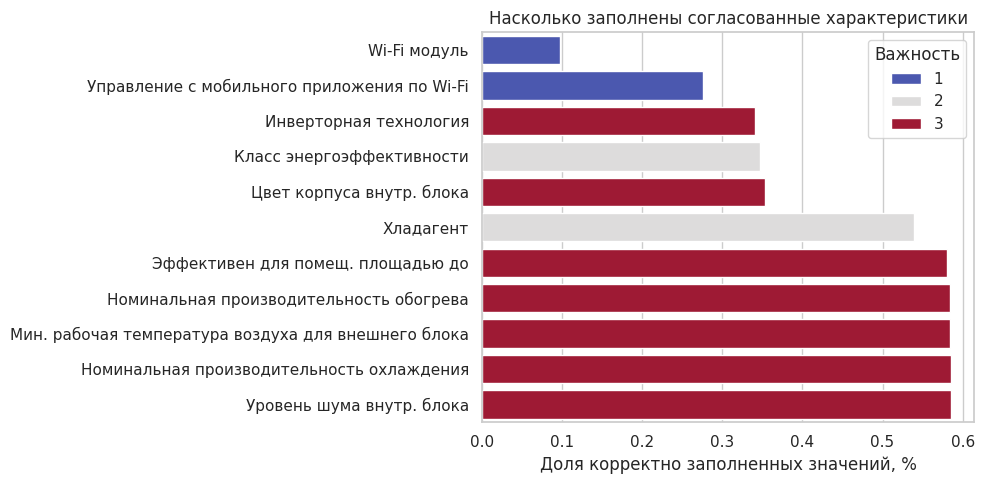

In [16]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=business_cov_report.sort_values("valid_coverage"),
    x="valid_coverage",
    y="characteristic_name",
    orient="h",
    hue="importance",
    dodge=False,
    palette="coolwarm",
)
plt.title("Насколько заполнены согласованные характеристики")
plt.xlabel("Доля корректно заполненных значений, %")
plt.ylabel("")
plt.legend(title="Важность")
plt.tight_layout()
plt.savefig(ARTIFACT_PATHS["visualizations"] / "business_coverage.png", dpi=150)
plt.show()

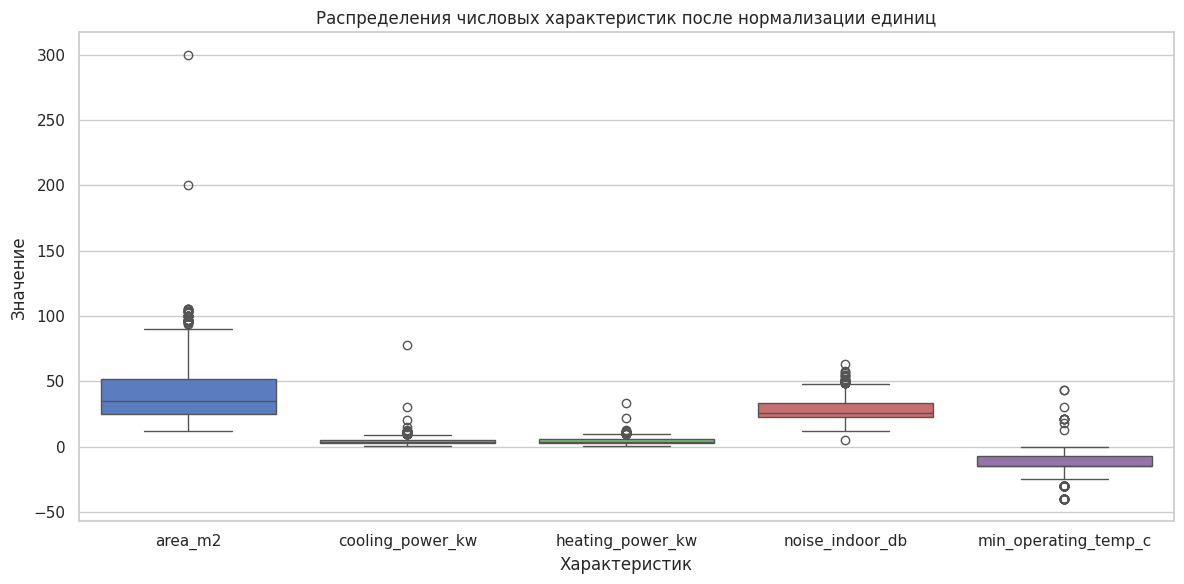

In [17]:
numeric_plot_cols = [
    "area_m2",
    "cooling_power_kw",
    "heating_power_kw",
    "noise_indoor_db",
    "min_operating_temp_c",
]
numeric_df = core_df[numeric_plot_cols].dropna(how="all").copy()
numeric_df = pd.melt(
    numeric_df,
    value_vars=numeric_plot_cols,
    var_name="feature",
    value_name="value",
)
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=numeric_df,
    x="feature",
    y="value",
    hue="feature",
    legend=False,
    palette="muted",
)
plt.title("Распределения числовых характеристик после нормализации единиц")
plt.ylabel("Значение")
plt.xlabel("Характеристик")
plt.tight_layout()
plt.savefig(ARTIFACT_PATHS["visualizations"] / "numeric_distributions.png", dpi=150)
plt.show()

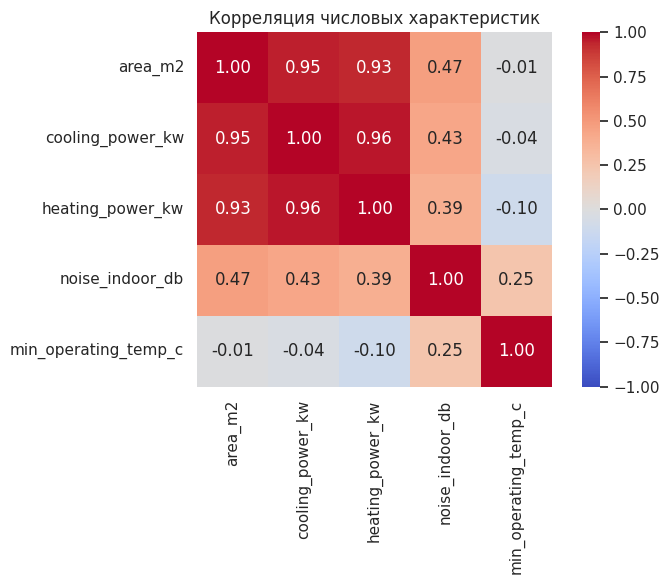

In [18]:
corr_cols = [c for c in core_numeric_fields if c in core_df.columns]
corr = core_df[corr_cols].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Корреляция числовых характеристик")
plt.tight_layout()
plt.savefig(ARTIFACT_PATHS["visualizations"] / "numeric_correlation_heatmap.png", dpi=150)
plt.show()

In [19]:
def build_tfidf_matrix(names: pd.Series):
    vectorizer = TfidfVectorizer(
        lowercase=True,
        min_df=2,
        max_features=50000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        token_pattern=r"(?u)\b[A-Za-zА-Яа-яЁё0-9]+\b",
        dtype=np.float32,
    )
    X = vectorizer.fit_transform(names.fillna("").astype(str))
    LOGGER.info("TF-IDF matrix shape: %s", X.shape)
    return vectorizer, X

text_vectorizer, X_text = build_tfidf_matrix(core_df["normalized_name"])
text_sim_matrix = cosine_similarity(X_text, X_text)
id_to_pos = {str(pid): pos for pos, pid in enumerate(core_df["id"].astype(str).tolist())}

2026-11-20 07:57:03 | INFO    | analog_v3 | TF-IDF matrix shape: (7339, 5887)


In [20]:
ground_truth = build_analog_ground_truth(core_df)
print("Продукты, имеющие аналоги в текущем наборе данных:", len(ground_truth))
print("Истинные аналоговые пары в текущем наборе данных:", sum(len(v) for v in ground_truth.values()))

Продукты, имеющие аналоги в текущем наборе данных: 1168
Истинные аналоговые пары в текущем наборе данных: 16407


In [21]:
raw_diag = diagnose_raw_analogs(raw_records)
print(json.dumps(raw_diag, ensure_ascii=False, indent=2))
save_json(raw_diag, ARTIFACT_PATHS["metrics"] / "raw_analogs_diagnosis.json")

{
  "total_rows": 8591,
  "empty_id_rows": 0,
  "unique_non_empty_ids": 8591,
  "rows_with_analogs": 1583,
  "unique_ids_with_any_analog": 1583,
  "duplicated_id_count": 0,
  "conflict_duplicated_id_count": 0,
  "conflict_duplicated_id_sample": [],
  "raw_analog_references_count": 20168,
  "unique_raw_analog_targets": 439
}
2026-11-20 07:57:04 | INFO    | analog_v3 | JSON saved: artifacts/metrics/raw_analogs_diagnosis.json


PosixPath('artifacts/metrics/raw_analogs_diagnosis.json')

In [22]:
ground_truth = build_analog_ground_truth(core_df)
profile_diag = diagnose_profile_stage(
    profiles_df=profiles_df,
    core_df=core_df,
    ground_truth=ground_truth,
)
print(json.dumps(profile_diag, ensure_ascii=False, indent=2))
save_json(profile_diag, ARTIFACT_PATHS["metrics"] / "profile_stage_analogs_diagnosis.json")

{
  "profiles_rows": 8591,
  "profiles_unique_ids": 8591,
  "profiles_ids_with_analogs": 1583,
  "core_rows": 7339,
  "core_unique_ids": 7339,
  "core_ids_with_analogs": 1168,
  "ground_truth_queries": 1168,
  "core_queries_with_analogs_but_not_in_ground_truth": 0,
  "core_analog_targets_count": 437,
  "core_analog_targets_present_in_core": 435,
  "core_analog_targets_missing_in_core": 2,
  "missing_target_sample": [
    "01M758XFVCSBV06Y7DK7M9194D",
    "01M7SQNA8HCR77GVWM2J6PMX39"
  ],
  "ground_truth_lost_queries_sample": []
}
2026-11-20 07:57:04 | INFO    | analog_v3 | JSON saved: artifacts/metrics/profile_stage_analogs_diagnosis.json


PosixPath('artifacts/metrics/profile_stage_analogs_diagnosis.json')

In [23]:
ground_truth_query_ids = sorted(ground_truth.keys())
if len(ground_truth_query_ids) >= 10:
    diagnostic_query_ids, control_query_ids = train_test_split(
        ground_truth_query_ids,
        test_size=CONFIG.TEST_SIZE,
        random_state=CONFIG.RANDOM_STATE,
    )
    diagnostic_ground_truth = {
        query_id: ground_truth[query_id]
        for query_id in diagnostic_query_ids
    }
    control_ground_truth = {
        query_id: ground_truth[query_id]
        for query_id in control_query_ids
    }
else:
    diagnostic_ground_truth = ground_truth
    control_ground_truth = {}
split_info = {
    "total_queries_with_analogs": len(ground_truth_query_ids),
    "diagnostic_queries": len(diagnostic_ground_truth),
    "control_queries": len(control_ground_truth),
    "test_size": CONFIG.TEST_SIZE,
    "random_state": CONFIG.RANDOM_STATE,
    "comment": (
        "Для задачи информационного поиска разделение выполнено по идентификаторам "
        "запросов, чтобы не допустить повторного появления одного и того же товара "
        "в разных частях выборки. Полное обучение модели не выполнялось из-за "
        "низкого качества поля Analogs, поэтому сплит используется как диагностический."
    ),
}
print(json.dumps(split_info, ensure_ascii=False, indent=2))
save_json(split_info, ARTIFACT_PATHS["metrics"] / "split_information.json")

{
  "total_queries_with_analogs": 1168,
  "diagnostic_queries": 934,
  "control_queries": 234,
  "test_size": 0.2,
  "random_state": 42,
  "comment": "Для задачи информационного поиска разделение выполнено по идентификаторам запросов, чтобы не допустить повторного появления одного и того же товара в разных частях выборки. Полное обучение модели не выполнялось из-за низкого качества поля Analogs, поэтому сплит используется как диагностический."
}
2026-11-20 07:57:04 | INFO    | analog_v3 | JSON saved: artifacts/metrics/split_information.json


PosixPath('artifacts/metrics/split_information.json')

In [24]:
analogs_validation = validate_analogs_with_business_rules(
    core_df,
    ground_truth,
    threshold=0.60,
    min_confidence=0.50,
)

print(json.dumps(
    {k: v for k, v in analogs_validation.items() if k != "failed_examples"},
    ensure_ascii=False,
    indent=2,
))

save_json(analogs_validation, ARTIFACT_PATHS["metrics"] / "analogs_business_validation.json")

{
  "threshold": 0.6,
  "min_confidence": 0.5,
  "total_checked": 16407,
  "passed": 8175,
  "failed": 8232,
  "failed_hard_fail": 0,
  "failed_score": 70,
  "failed_no_valid_feature_data": 8162,
  "failed_low_confidence": 0,
  "evaluable_total": 8245,
  "evaluable_rate": 0.5025294081794356,
  "pass_rate": 0.4982629365514719,
  "pass_rate_evaluable": 0.9915100060642814,
  "mean_score": 0.6496804899151025,
  "mean_confidence": 0.4037081056188753,
  "hard_fail_field_counts": {}
}
2026-11-20 07:57:06 | INFO    | analog_v3 | JSON saved: artifacts/metrics/analogs_business_validation.json


PosixPath('artifacts/metrics/analogs_business_validation.json')

In [25]:
score_df = collect_business_score_distribution(core_df, ground_truth)
print("Total pairs:", len(score_df))
print()
print("Score describe:")
print(score_df["score"].describe())
print()
print("Most frequent rounded scores:")
print(
    score_df["score"]
    .round(3)
    .value_counts()
    .sort_index()
)

Total pairs: 16407

Score describe:
count    16407.000000
mean         0.649680
std          0.171088
min          0.500000
25%          0.500000
50%          0.527778
75%          0.833333
max          1.000000
Name: score, dtype: float64

Most frequent rounded scores:
score
0.500    8162
0.528      70
0.639    1756
0.667     955
0.724       1
0.729       1
0.750       8
0.756       1
0.770       3
0.771      40
0.776       2
0.788       2
0.792     224
0.799      51
0.812       3
0.816       4
0.819     167
0.833    1622
0.838       3
0.840       1
0.844       4
0.846       2
0.850       1
0.851       1
0.858       2
0.859       2
0.861    1656
0.863       2
0.872      11
0.884      11
0.886       2
0.889      14
0.896       2
0.901       2
0.903      90
0.910       2
0.917      10
0.920       2
0.924      16
0.925       2
0.926       2
0.931     274
0.944     260
0.951       4
0.958       8
0.972     933
1.000      16
Name: count, dtype: int64


In [26]:
failed_at_060 = score_df[
    (score_df["hard_fail"] == False)
    & (score_df["status"] != "insufficient_data")
    & (score_df["score"] < 0.60)
]
print("Failed at threshold 0.60:", len(failed_at_060))
sample_failed = failed_at_060.head(3)
for row in sample_failed.itertuples(index=False):
    print()
    print("Query id:", row.query_id)
    print("Analog id:", row.analog_id)
    print("Score:", row.score)
    print("Active fields:", row.active_fields)
    print("Missing fields:", row.missing_fields)

Failed at threshold 0.60: 8232

Query id: 01KTRZNZ8CSGEK2PTXG01H7GA3
Analog id: 01KTSCSMHJX2S8PTKT2SJS8B8G
Score: 0.5277777777777777
Active fields: is_inverter|area_m2|cooling_power_kw|heating_power_kw|noise_indoor_db|min_operating_temp_c|color_inner_body|has_wifi_module|has_wifi_app_control|refrigerant|energy_class
Missing fields: is_inverter|area_m2|color_inner_body|has_wifi_module|has_wifi_app_control|energy_class

Query id: 01KTRZNZ8CSGEK2PTXG01H7GA3
Analog id: 01KTSCSSCN2GD1RR2N769ER7H5
Score: 0.5277777777777777
Active fields: is_inverter|area_m2|cooling_power_kw|heating_power_kw|noise_indoor_db|min_operating_temp_c|color_inner_body|has_wifi_module|has_wifi_app_control|refrigerant|energy_class
Missing fields: is_inverter|area_m2|color_inner_body|has_wifi_module|has_wifi_app_control|energy_class

Query id: 01KTRZNZ8CSGEK2PTXG01H7GA3
Analog id: 01KTSCSKGDE9XH7MPKNQTCRBBJ
Score: 0.5277777777777777
Active fields: is_inverter|area_m2|cooling_power_kw|heating_power_kw|noise_indoor_db|mi

In [27]:
evaluable_source = build_evaluable_ground_truth(
    df=core_df,
    ground_truth=ground_truth,
)
evaluable_ground_truth = evaluable_source["evaluable_ground_truth"]
evaluable_source_stats = evaluable_source["stats"]
print(json.dumps(evaluable_source_stats, ensure_ascii=False, indent=2))

{
  "total_pairs": 16407,
  "evaluable_pairs": 8245,
  "uncheckable_pairs": 8162,
  "evaluable_rate": 0.5025294081794356,
  "queries_total": 1168,
  "queries_with_evaluable_analogs": 1057,
  "examples_uncheckable": [
    {
      "query_id": "01M758XAFP9TD91RBVJK9FYN6E",
      "analog_id": "01M758XF5XT9MS4VTW48RSKH0W",
      "valid_fields": [],
      "missing_fields": [
        "is_inverter",
        "area_m2",
        "cooling_power_kw",
        "heating_power_kw",
        "noise_indoor_db",
        "min_operating_temp_c",
        "color_inner_body",
        "has_wifi_module",
        "has_wifi_app_control",
        "refrigerant",
        "energy_class"
      ],
      "confidence": 0.0
    },
    {
      "query_id": "01M758XAFP9TD91RBVJK9FYN6E",
      "analog_id": "01M758XETQCZF93PK4NACM039N",
      "valid_fields": [],
      "missing_fields": [
        "is_inverter",
        "area_m2",
        "cooling_power_kw",
        "heating_power_kw",
        "noise_indoor_db",
        "min_opera

In [28]:
evaluable_analogs_validation = validate_analogs_with_business_rules(
    df=core_df,
    ground_truth=evaluable_ground_truth,
    threshold=0.60,
    min_confidence=0.0,
)
print(
    json.dumps(
        {
            k: v
            for k, v in evaluable_analogs_validation.items()
            if k != "failed_examples"
        },
        ensure_ascii=False,
        indent=2,
    )
)

{
  "threshold": 0.6,
  "min_confidence": 0.0,
  "total_checked": 8245,
  "passed": 8175,
  "failed": 70,
  "failed_hard_fail": 0,
  "failed_score": 70,
  "failed_no_valid_feature_data": 0,
  "failed_low_confidence": 0,
  "evaluable_total": 8245,
  "evaluable_rate": 1.0,
  "pass_rate": 0.9915100060642814,
  "pass_rate_evaluable": 0.9915100060642814,
  "mean_score": 0.7978541901803623,
  "mean_confidence": 0.8033521999865237,
  "hard_fail_field_counts": {}
}


In [29]:
failed_evaluable_pairs = export_failed_evaluable_pairs(
    df=core_df,
    ground_truth=evaluable_ground_truth,
    threshold=0.60,
    limit=200,
)
failed_evaluable_pairs.to_csv(
    ARTIFACT_PATHS["reports"] / "failed_evaluable_analog_pairs.csv",
    index=False,
    encoding="utf-8-sig",
)
print(len(failed_evaluable_pairs))
failed_evaluable_pairs.head(3)

70


,query_id,query_name,analog_id,analog_name,score,hard_fail,hard_fail_fields,valid_fields,core_valid_fields,confidence
0,01KTRZNZ8CSGEK2PTXG01H7GA3,Сплит-система настенного типа MDV Aurora Design Gold On/Off R32 MDSA-09HRN8 ...,01KTSCSMHJX2S8PTKT2SJS8B8G,Сплит-система Ballu Lagoon BSD-09HN8 комплект,0.527778,False,,cooling_power_kw|heating_power_kw|noise_indoor_db|min_operating_temp_c|refri...,cooling_power_kw|heating_power_kw,0.527778
1,01KTRZNZ8CSGEK2PTXG01H7GA3,Сплит-система настенного типа MDV Aurora Design Gold On/Off R32 MDSA-09HRN8 ...,01KTSCSKGDE9XH7MPKNQTCRBBJ,Сплит-система Royal Thermo Siena RTS-09HN8_V2 комплект,0.527778,False,,cooling_power_kw|heating_power_kw|noise_indoor_db|min_operating_temp_c|refri...,cooling_power_kw|heating_power_kw,0.527778
2,01KTRZNZ8CSGEK2PTXG01H7GA3,Сплит-система настенного типа MDV Aurora Design Gold On/Off R32 MDSA-09HRN8 ...,01KTSCSSCN2GD1RR2N769ER7H5,Сплит-система Royal Thermo Siena RTS-09HN8_V3 комплект,0.527778,False,,cooling_power_kw|heating_power_kw|noise_indoor_db|min_operating_temp_c|refri...,cooling_power_kw|heating_power_kw,0.527778


In [30]:
source_quality_result = compute_analogs_source_quality(
    df=core_df,
    ground_truth=ground_truth,
    threshold=0.60,
)
source_quality = source_quality_result["source_quality_metrics"]
evaluable_ground_truth = source_quality_result["evaluable_ground_truth"]
print(json.dumps(source_quality, ensure_ascii=False, indent=2))
save_json(
    {
        "source_quality_metrics": source_quality,
        "all_pairs_validation": source_quality_result["all_pairs_validation"],
        "evaluable_pairs_validation": source_quality_result["evaluable_pairs_validation"],
    },
    ARTIFACT_PATHS["metrics"] / "analogs_source_quality.json",
)

{
  "threshold": 0.6,
  "total_pairs": 16407,
  "evaluable_pairs": 8245,
  "uncheckable_pairs": 8162,
  "evaluable_rate": 0.5025294081794356,
  "uncheckable_rate": 0.4974705918205644,
  "passed_all": 8175,
  "pass_rate_all": 0.4982629365514719,
  "passed_evaluable": 8175,
  "pass_rate_evaluable": 0.9915100060642814,
  "failed_score_all": 70,
  "failed_hard_fail_all": 0,
  "failed_no_valid_feature_data_all": 8162,
  "failed_score_evaluable": 70,
  "failed_hard_fail_evaluable": 0,
  "mean_score_evaluable": 0.7978541901803623,
  "mean_confidence_evaluable": 0.8033521999865237
}
2026-11-20 07:57:15 | INFO    | analog_v3 | JSON saved: artifacts/metrics/analogs_source_quality.json


PosixPath('artifacts/metrics/analogs_source_quality.json')

In [31]:
MIN_EVALUABLE_RATE_FOR_VALIDATION = 0.60
MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION = 0.55
WEAK_EVALUABLE_RATE = 0.45
WEAK_PASS_RATE_EVALUABLE = 0.90
USE_TRUE_ANALOGS_VALIDATION = (
    source_quality["evaluable_rate"] >= MIN_EVALUABLE_RATE_FOR_VALIDATION
    and source_quality["pass_rate_evaluable"] >= MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION
)
USE_WEAK_ANALOGS_SOURCE = (
    not USE_TRUE_ANALOGS_VALIDATION
    and source_quality["evaluable_rate"] >= WEAK_EVALUABLE_RATE
    and source_quality["pass_rate_evaluable"] >= WEAK_PASS_RATE_EVALUABLE
)
if USE_TRUE_ANALOGS_VALIDATION:
    selected_mode = "A_true_analogs_validation"
    selected_reason = "Analogs можно использовать как полноценный эталон для диагностики и слабой разметки."
elif USE_WEAK_ANALOGS_SOURCE:
    selected_mode = "B_business_heuristics_with_weak_evaluable_source"
    selected_reason = (
        "Полный Analogs нельзя использовать как чистый эталон из-за низкой проверяемости, "
        "но среди технических пар его качество высокое. "
        "Можно использовать проверяемую часть как слабую разметку."
    )
else:
    selected_mode = "B_business_heuristics"
    selected_reason = "Analogs слишком шумный или слишком непроверяемый, используется бизнес-скоринг."
mode_info = {
    "USE_TRUE_ANALOGS_VALIDATION": bool(USE_TRUE_ANALOGS_VALIDATION),
    "USE_WEAK_ANALOGS_SOURCE": bool(USE_WEAK_ANALOGS_SOURCE),
    "selected_mode": selected_mode,
    "reason": selected_reason,
    "thresholds": {
        "MIN_EVALUABLE_RATE_FOR_VALIDATION": MIN_EVALUABLE_RATE_FOR_VALIDATION,
        "MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION": MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION,
        "WEAK_EVALUABLE_RATE": WEAK_EVALUABLE_RATE,
        "WEAK_PASS_RATE_EVALUABLE": WEAK_PASS_RATE_EVALUABLE,
    },
    "source_quality_metrics": source_quality,
}
print(json.dumps(mode_info, ensure_ascii=False, indent=2))
save_json(mode_info, ARTIFACT_PATHS["metrics"] / "mode_selection_v2.json")

{
  "USE_TRUE_ANALOGS_VALIDATION": false,
  "USE_WEAK_ANALOGS_SOURCE": true,
  "selected_mode": "B_business_heuristics_with_weak_evaluable_source",
  "reason": "Полный Analogs нельзя использовать как чистый эталон из-за низкой проверяемости, но среди технических пар его качество высокое. Можно использовать проверяемую часть как слабую разметку.",
  "thresholds": {
    "MIN_EVALUABLE_RATE_FOR_VALIDATION": 0.6,
    "MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION": 0.55,
    "WEAK_EVALUABLE_RATE": 0.45,
    "WEAK_PASS_RATE_EVALUABLE": 0.9
  },
  "source_quality_metrics": {
    "threshold": 0.6,
    "total_pairs": 16407,
    "evaluable_pairs": 8245,
    "uncheckable_pairs": 8162,
    "evaluable_rate": 0.5025294081794356,
    "uncheckable_rate": 0.4974705918205644,
    "passed_all": 8175,
    "pass_rate_all": 0.4982629365514719,
    "passed_evaluable": 8175,
    "pass_rate_evaluable": 0.9915100060642814,
    "failed_score_all": 70,
    "failed_hard_fail_all": 0,
    "failed_no_valid_feature_data_al

PosixPath('artifacts/metrics/mode_selection_v2.json')

In [32]:
recommender = AnalogRecommender(
    df=core_df,
    business_weights=BUSINESS_WEIGHTS,
    text_sim_matrix=text_sim_matrix,
    id_to_pos=id_to_pos,
)
core_numeric_for_demo = [
    "area_m2",
    "cooling_power_kw",
    "heating_power_kw",
    "noise_indoor_db",
    "min_operating_temp_c",
]
elig = core_df[core_numeric_for_demo].notna().sum(axis=1) >= 4
if elig.any():
    demo_product = core_df[elig].iloc[0]
else:
    demo_product = core_df.iloc[0]
QUERY_ID = str(demo_product["id"])
print("Query id:", QUERY_ID)
print("Query name:", demo_product.get("name"))
print("Query area_m2:", demo_product.get("area_m2"))
print("Query cooling_power_kw:", demo_product.get("cooling_power_kw"))
print("Query heating_power_kw:", demo_product.get("heating_power_kw"))
print("Query noise_indoor_db:", demo_product.get("noise_indoor_db"))
print("Query min_operating_temp_c:", demo_product.get("min_operating_temp_c"))
demo_results = recommender.get_analogs_by_id(QUERY_ID, k=3)
demo_df = pd.DataFrame(
    [
        {
            "id": item["id"],
            "name": item["name"],
            "score": item["score"],
            "area_m2": item["area_m2"],
            "cooling_power_kw": item["cooling_power_kw"],
            "heating_power_kw": item["heating_power_kw"],
            "noise_indoor_db": item["noise_indoor_db"],
            "min_operating_temp_c": item["min_operating_temp_c"],
            "is_inverter": item["is_inverter"],
            "has_wifi_module": item["has_wifi_module"],
            "color_inner_body": item["color_inner_body"],
            "refrigerant": item["refrigerant"],
            "energy_class": item["energy_class"],
        }
        for item in demo_results
    ]
)

Query id: 01KTTYDTX5H6JKKW2XX5Q3YDC7
Query name: Инверторная сплит система Mitsubishi SKM20ZSP-W (Белый)
Query area_m2: 20.0
Query cooling_power_kw: 2.0
Query heating_power_kw: 3.0
Query noise_indoor_db: 22.0
Query min_operating_temp_c: nan


In [33]:
demo_df

,id,name,score,area_m2,cooling_power_kw,heating_power_kw,noise_indoor_db,min_operating_temp_c,is_inverter,has_wifi_module,color_inner_body,refrigerant,energy_class
0,01KTTYDTVC791NAF0MPJD5TFM2,Инверторная сплит система Mitsubishi SRK20ZTL-W (Белый),0.638889,20.0,2.0,2.7,19.0,-20.0,True,True,None,R32,None
1,01KTTYDTSM36WC6501V0RD7E8D,Инверторная сплит система Mitsubishi SRK20ZS-W Premium (Белый),0.638889,20.0,2.0,2.7,19.0,-15.0,True,None,None,R32,None
2,01KTTYDTR79HYJ27M6KGGAK6Y7,Инверторная сплит система Mitsubishi SRK20ZSX-W DIAMOND (Белый),0.638889,20.0,2.0,2.7,19.0,-20.0,True,None,None,R32,None


In [34]:
save_json(demo_results, ARTIFACT_PATHS["reports"] / "demo_analog_results.json")

2026-11-20 07:57:15 | INFO    | analog_v3 | JSON saved: artifacts/reports/demo_analog_results.json


PosixPath('artifacts/reports/demo_analog_results.json')

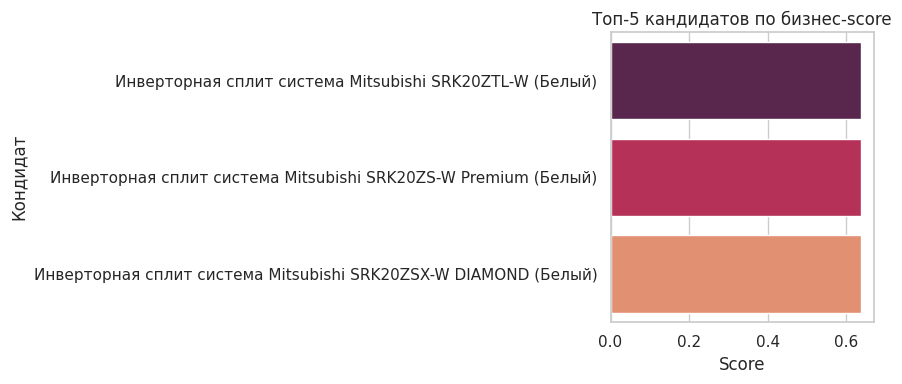

In [35]:
if demo_df.empty:
    print("Демо-кандидаты не найдены.")
else:
    plt.figure(figsize=(9, 4))
    sns.barplot(
        data=demo_df.head(10),
        x="score",
        y=demo_df.head(3)["name"].astype(str),
        hue="name",
        orient="h",
        palette="rocket",
    )
    plt.title("Топ-5 кандидатов по бизнес-score")
    plt.xlabel("Score")
    plt.ylabel("Кондидат")
    plt.tight_layout()
    plt.savefig(ARTIFACT_PATHS["visualizations"] / "demo_topk_scores.png", dpi=150)
    plt.show()

In [36]:
def precision_at_k(true_analogs: Set[str], predicted_ids: List[str], k: int) -> float:
    if k <= 0 or not predicted_ids:
        return 0.0
    top_k = predicted_ids[:k]
    hits = len(true_analogs.intersection(set(top_k)))
    return hits / float(k)

def recall_at_k(true_analogs: Set[str], predicted_ids: List[str], k: int) -> float:
    if not true_analogs:
        return 0.0
    top_k = predicted_ids[:k]
    hits = len(true_analogs.intersection(set(top_k)))
    return hits / float(len(true_analogs))

def reciprocal_rank(true_analogs: Set[str], predicted_ids: List[str]) -> float:
    for rank, product_id in enumerate(predicted_ids, start=1):
        if product_id in true_analogs:
            return 1.0 / float(rank)
    return 0.0

def hit_rate_at_k(true_analogs: Set[str], predicted_ids: List[str], k: int) -> float:
    if not true_analogs:
        return 0.0
    return float(bool(true_analogs.intersection(set(predicted_ids[:k]))))

def evaluate_retrieval(
    recommender: AnalogRecommender,
    ground_truth: Dict[str, Set[str]],
    k_list: List[int],
) -> Dict[str, Any]:
    if not ground_truth:
        return {
            "status": "no_ground_truth",
            "message": "Поле Analogs отсутствует или не покрывает текущую подвыборку.",
        }
    metrics = {}
    for k in k_list:
        metrics[f"precision@{k}"] = []
        metrics[f"recall@{k}"] = []
        metrics[f"hitrate@{k}"] = []
    mrr_values = []
    for query_id, true_analogs in ground_truth.items():
        predicted = recommender.get_analogs_by_id(query_id=query_id, k=max(k_list))
        predicted_ids = [item["id"] for item in predicted]
        for k in k_list:
            metrics[f"precision@{k}"].append(precision_at_k(true_analogs, predicted_ids, k))
            metrics[f"recall@{k}"].append(recall_at_k(true_analogs, predicted_ids, k))
            metrics[f"hitrate@{k}"].append(hit_rate_at_k(true_analogs, predicted_ids, k))
        mrr_values.append(reciprocal_rank(true_analogs, predicted_ids))
    result = {
        "n_queries": len(ground_truth),
        "mrr": float(np.mean(mrr_values)) if mrr_values else 0.0,
    }
    for k in k_list:
        result[f"precision@{k}"] = float(np.mean(metrics[f"precision@{k}"]))
        result[f"recall@{k}"] = float(np.mean(metrics[f"recall@{k}"]))
        result[f"hitrate@{k}"] = float(np.mean(metrics[f"hitrate@{k}"]))
    return result

retrieval_metrics_control = evaluate_retrieval(
    recommender=recommender,
    ground_truth=control_ground_truth if control_ground_truth else ground_truth,
    k_list=CONFIG.K_LIST,
)

retrieval_metrics_diagnostic = evaluate_retrieval(
    recommender=recommender,
    ground_truth=diagnostic_ground_truth,
    k_list=CONFIG.K_LIST,
)

retrieval_metrics = evaluate_retrieval(
    recommender=recommender,
    ground_truth=ground_truth,
    k_list=CONFIG.K_LIST,
)
print(json.dumps(retrieval_metrics, ensure_ascii=False, indent=2))
save_json(retrieval_metrics_diagnostic, ARTIFACT_PATHS["metrics"] / "retrieval_metrics_diagnostic.json")
save_json(retrieval_metrics_control, ARTIFACT_PATHS["metrics"] / "retrieval_metrics_control.json")
save_json(retrieval_metrics, ARTIFACT_PATHS["metrics"] / "retrieval_metrics.json")

{
  "n_queries": 1168,
  "mrr": 0.2676814932594042,
  "precision@1": 0.14126712328767124,
  "recall@1": 0.028146504278138893,
  "hitrate@1": 0.14126712328767124,
  "precision@3": 0.13356164383561642,
  "recall@3": 0.07163404030180345,
  "hitrate@3": 0.2988013698630137,
  "precision@5": 0.1517123287671233,
  "recall@5": 0.1262747870629354,
  "hitrate@5": 0.4486301369863014,
  "precision@10": 0.18955479452054794,
  "recall@10": 0.2794638997130356,
  "hitrate@10": 0.6626712328767124
}
2026-11-20 07:59:06 | INFO    | analog_v3 | JSON saved: artifacts/metrics/retrieval_metrics_diagnostic.json
2026-11-20 07:59:06 | INFO    | analog_v3 | JSON saved: artifacts/metrics/retrieval_metrics_control.json
2026-11-20 07:59:06 | INFO    | analog_v3 | JSON saved: artifacts/metrics/retrieval_metrics.json


PosixPath('artifacts/metrics/retrieval_metrics.json')

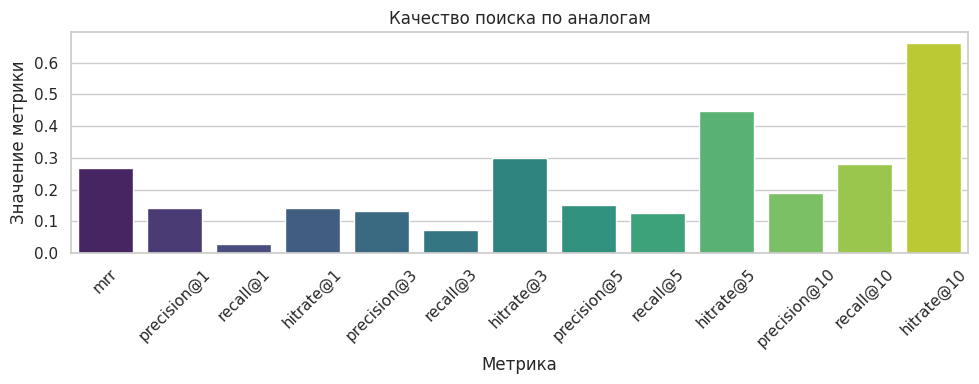

In [37]:
if "precision@5" in retrieval_metrics:
    metric_df = pd.DataFrame(
        {
            "metric": list(retrieval_metrics.keys()),
            "value": [v for k, v in retrieval_metrics.items() if isinstance(v, (int, float))],
        }
    )
    metric_df = metric_df[
        metric_df["metric"].str.contains(r"@|mrr", case=False)
    ].copy()
    if not metric_df.empty:
        plt.figure(figsize=(10, 4))
        sns.barplot(
            data=metric_df,
            x="metric",
            y="value",
            hue="metric",
            palette="viridis",
            legend=False,
        )
        plt.title("Качество поиска по аналогам")
        plt.ylabel("Значение метрики")
        plt.xlabel("Метрика")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(ARTIFACT_PATHS["visualizations"] / "retrieval_metrics.png", dpi=150)
        plt.show()
else:
    print("Метрики поиска отсутствуют: нет достоверных данных по аналогам.")

In [38]:
def get_candidate_positions_compat(
    recommender,
    query_id: str,
    max_candidates: int
) -> List[int]:
    if not hasattr(recommender, "id_to_idx"):
        raise AttributeError("У recommender нет id_to_idx")
    if query_id not in recommender.id_to_idx:
        return []
    if hasattr(recommender, "get_candidate_positions"):
        try:
            return recommender.get_candidate_positions(
                query_id=query_id,
                max_candidates=max_candidates,
            )
        except TypeError:
            pass
    if hasattr(recommender, "_candidate_positions_with_text_scores"):
        q_idx = recommender.id_to_idx[query_id]
        try:
            candidates = recommender._candidate_positions_with_text_scores(q_idx)
            return [int(pos) for pos, _ in candidates]
        except Exception as exc:
            LOGGER.warning("Не удалось получить candidates через новый сервис: %s", exc)
            return []

def candidate_ids_for_query(
    recommender,
    query_id: str,
    max_candidates: int,
) -> Set[str]:
    positions = get_candidate_positions_compat(
        recommender=recommender,
        query_id=query_id,
        max_candidates=max_candidates,
    )
    candidate_ids = set()
    for pos in positions:
        pos = int(pos)
        try:
            product_id = str(recommender.df.iloc[pos]["id"])
            candidate_ids.add(product_id)
        except Exception:
            continue
    return candidate_ids

def evaluate_candidate_retrieval(
    recommender,
    ground_truth: Dict[str, Set[str]],
    max_candidates: int,
) -> Dict[str, float]:
    total_queries = 0
    queries_with_candidate_hit = 0
    total_true_pairs = 0
    covered_true_pairs = 0
    total_candidate_count = 0
    for query_id, true_ids in ground_truth.items():
        if query_id not in recommender.id_to_idx:
            continue
        if not true_ids:
            continue
        candidate_ids = candidate_ids_for_query(
            recommender=recommender,
            query_id=query_id,
            max_candidates=max_candidates,
        )
        total_queries += 1
        total_candidate_count += len(candidate_ids)
        if candidate_ids & true_ids:
            queries_with_candidate_hit += 1
        for true_id in true_ids:
            total_true_pairs += 1
            if true_id in candidate_ids:
                covered_true_pairs += 1
    return {
        "max_candidates": float(max_candidates),
        "total_queries": float(total_queries),
        "queries_with_candidate_hit": float(queries_with_candidate_hit),
        "candidate_recall": float(queries_with_candidate_hit / max(total_queries, 1)),
        "total_true_pairs": float(total_true_pairs),
        "covered_true_pairs": float(covered_true_pairs),
        "true_analog_pair_coverage": float(covered_true_pairs / max(total_true_pairs, 1)),
        "average_candidate_count": float(total_candidate_count / max(total_queries, 1)),
    }
    
candidate_retrieval_metrics = evaluate_candidate_retrieval(
    recommender=recommender,
    ground_truth=ground_truth,
    max_candidates=CONFIG.CANDIDATES_PER_QUERY_MAX,
)
print(json.dumps(candidate_retrieval_metrics, ensure_ascii=False, indent=2))
save_json(
    candidate_retrieval_metrics,
    ARTIFACT_PATHS["metrics"] / "candidate_retrieval_metrics.json",
)

{
  "max_candidates": 300.0,
  "total_queries": 1168.0,
  "queries_with_candidate_hit": 1151.0,
  "candidate_recall": 0.985445205479452,
  "total_true_pairs": 16407.0,
  "covered_true_pairs": 7433.0,
  "true_analog_pair_coverage": 0.453038337295057,
  "average_candidate_count": 300.0
}
2026-11-20 07:59:35 | INFO    | analog_v3 | JSON saved: artifacts/metrics/candidate_retrieval_metrics.json


PosixPath('artifacts/metrics/candidate_retrieval_metrics.json')

In [39]:
def evaluate_business_quality_on_candidate_sets(
    recommender,
    ground_truth: Dict[str, Set[str]],
    threshold: float = 0.60,
    max_queries: int = 300,
    max_candidates: int = 200,
    random_state: int = 42,
) -> Dict[str, Any]:
    rng = np.random.default_rng(random_state)
    query_ids = sorted(list(ground_truth.keys()))
    query_ids = [q for q in query_ids if q in recommender.id_to_idx]
    if len(query_ids) > max_queries:
        query_ids = rng.choice(query_ids, size=max_queries, replace=False).tolist()
    total_candidates = 0
    passed_candidates = 0
    hard_fail_candidates = 0
    score_values = []
    top1_total = 0
    top1_pass = 0
    for query_id in query_ids:
        positions = get_candidate_positions_compat(
            recommender=recommender,
            query_id=query_id,
            max_candidates=max_candidates,
        )
        if not positions:
            continue
        try:
            query_row = recommender.df.iloc[recommender.id_to_idx[query_id]]
        except Exception:
            continue
        query_scores = []
        query_hard_fails = []
        for pos in positions:
            pos = int(pos)
            try:
                candidate_row = recommender.df.iloc[pos]
                scoring = business_pair_score(query_row, candidate_row)
            except Exception:
                continue
            total_candidates += 1
            score = float(scoring["score"])
            hard_fail = bool(scoring["hard_fail"])
            query_scores.append(score)
            query_hard_fails.append(hard_fail)
            score_values.append(score)
            if hard_fail:
                hard_fail_candidates += 1
            elif score >= threshold:
                passed_candidates += 1
        if query_scores:
            top1_index = int(np.argmax(query_scores))
            top1_total += 1
            if not query_hard_fails[top1_index] and query_scores[top1_index] >= threshold:
                top1_pass += 1
    return {
        "threshold": float(threshold),
        "max_candidates": int(max_candidates),
        "evaluated_queries": int(len(query_ids)),
        "total_candidates_evaluated": int(total_candidates),
        "passed_candidates": int(passed_candidates),
        "critical_reject_candidates": int(hard_fail_candidates),
        "business_pass_rate_on_candidates": float(passed_candidates / max(total_candidates, 1)),
        "critical_reject_rate_on_candidates": float(hard_fail_candidates / max(total_candidates, 1)),
        "average_candidate_score": float(np.mean(score_values)) if score_values else 0.0,
        "top1_pass_rate": float(top1_pass / max(top1_total, 1)),
    }

business_candidate_metrics = evaluate_business_quality_on_candidate_sets(
    recommender=recommender,
    ground_truth=ground_truth,
    threshold=0.60,
    max_queries=300,
    max_candidates=CONFIG.CANDIDATES_PER_QUERY_MAX,
    random_state=CONFIG.RANDOM_STATE,
)
print(json.dumps(business_candidate_metrics, ensure_ascii=False, indent=2))
save_json(
    business_candidate_metrics,
    ARTIFACT_PATHS["metrics"] / "business_candidate_metrics.json",
)

{
  "threshold": 0.6,
  "max_candidates": 300,
  "evaluated_queries": 300,
  "total_candidates_evaluated": 90000,
  "passed_candidates": 24045,
  "critical_reject_candidates": 48858,
  "business_pass_rate_on_candidates": 0.26716666666666666,
  "critical_reject_rate_on_candidates": 0.5428666666666667,
  "average_candidate_score": 0.6126466821402122,
  "top1_pass_rate": 0.8933333333333333
}
2026-11-20 07:59:49 | INFO    | analog_v3 | JSON saved: artifacts/metrics/business_candidate_metrics.json


PosixPath('artifacts/metrics/business_candidate_metrics.json')

,field,delta_percent,pairs,mean_baseline_score,mean_perturbed_score,mean_score_drop,hard_fail_rate
0,area_m2,0.05,181,0.801165,0.801149,0.000016,0.000000
1,area_m2,0.10,181,0.801165,0.799985,0.001180,0.000000
2,area_m2,0.20,181,0.801165,0.772954,0.028210,0.000000
3,area_m2,0.30,181,0.801165,0.721573,0.079592,0.000000
4,cooling_power_kw,0.05,184,0.796708,0.796601,0.000107,0.000000
5,cooling_power_kw,0.10,184,0.796708,0.795335,0.001372,0.000000
6,cooling_power_kw,0.20,184,0.796708,0.766857,0.029850,0.000000
7,cooling_power_kw,0.30,184,0.796708,0.714489,0.082219,0.000000
8,heating_power_kw,0.05,184,0.796708,0.796613,0.000095,0.000000
9,heating_power_kw,0.10,184,0.796708,0.795035,0.001672,0.000000


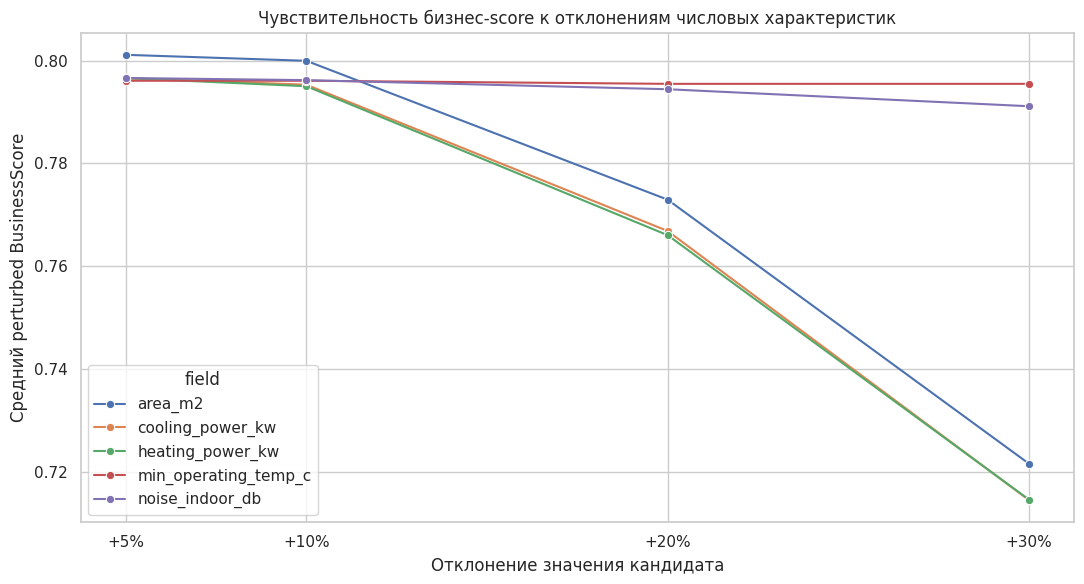

In [40]:
def evaluate_numeric_sensitivity(
    recommender,
    ground_truth: Dict[str, Set[str]],
    fields: List[str] = None,
    perturbations: List[float] = None,
    max_queries: int = 200,
    random_state: int = 42,
) -> pd.DataFrame:
    """
    Проверяет чувствительность бизнес-score к числовым отклонениям.
    Для реальной пары query -> top1 candidate:
    - candidate числовой признак увеличивается на x%;
    - пересчитывается business_score;
    - измеряется падение score.
    Это помогает показать robustness модели к шуму и выбросам.
    """
    if fields is None:
        fields = [
            "cooling_power_kw",
            "heating_power_kw",
            "area_m2",
            "noise_indoor_db",
            "min_operating_temp_c",
        ]
    if perturbations is None:
        perturbations = [0.05, 0.10, 0.20, 0.30]
    rng = np.random.default_rng(random_state)
    query_ids = sorted(list(ground_truth.keys()))
    query_ids = [q for q in query_ids if q in recommender.id_to_idx]
    if len(query_ids) > max_queries:
        query_ids = rng.choice(query_ids, size=max_queries, replace=False).tolist()
    results = []
    for query_id in query_ids:
        try:
            top1 = recommender.get_analogs_by_id(query_id=query_id, k=1)
        except Exception:
            continue
        if not top1:
            continue
        candidate_id = top1[0]["id"]
        try:
            query_row = recommender.df.iloc[recommender.id_to_idx[query_id]]
            candidate_row = recommender.df.iloc[recommender.id_to_idx[candidate_id]]
        except Exception:
            continue
        baseline = business_pair_score(query_row, candidate_row)
        for field in fields:
            value = pd.to_numeric(pd.Series([candidate_row.get(field)]), errors="coerce").iloc[0]
            if pd.isna(value):
                continue
            for delta in perturbations:
                perturbed_row = candidate_row.copy()
                perturbed_row[field] = float(value) * (1.0 + float(delta))
                perturbed_score = business_pair_score(query_row, perturbed_row)
                results.append(
                    {
                        "field": field,
                        "delta_percent": float(delta),
                        "baseline_score": float(baseline["score"]),
                        "perturbed_score": float(perturbed_score["score"]),
                        "score_drop": float(baseline["score"] - perturbed_score["score"]),
                        "perturbed_hard_fail": bool(perturbed_score["hard_fail"]),
                    }
                )
    df = pd.DataFrame(results)
    if df.empty:
        return df
    summary = (
        df.groupby(["field", "delta_percent"])
        .agg(
            pairs=("baseline_score", "count"),
            mean_baseline_score=("baseline_score", "mean"),
            mean_perturbed_score=("perturbed_score", "mean"),
            mean_score_drop=("score_drop", "mean"),
            hard_fail_rate=("perturbed_hard_fail", "mean"),
        )
        .reset_index()
        .sort_values(["field", "delta_percent"])
    )
    return summary

sensitivity_df = evaluate_numeric_sensitivity(
    recommender=recommender,
    ground_truth=ground_truth,
    fields=[
        "cooling_power_kw",
        "heating_power_kw",
        "area_m2",
        "noise_indoor_db",
        "min_operating_temp_c",
    ],
    perturbations=[0.05, 0.10, 0.20, 0.30],
    max_queries=200,
    random_state=CONFIG.RANDOM_STATE,
)
display(sensitivity_df)
if not sensitivity_df.empty:
    plt.figure(figsize=(11, 6))
    sns.lineplot(
        data=sensitivity_df,
        x="delta_percent",
        y="mean_perturbed_score",
        hue="field",
        marker="o",
    )
    plt.title("Чувствительность бизнес-score к отклонениям числовых характеристик")
    plt.xlabel("Отклонение значения кандидата")
    plt.ylabel("Средний perturbed BusinessScore")
    plt.xticks([0.05, 0.10, 0.20, 0.30], ["+5%", "+10%", "+20%", "+30%"])
    plt.tight_layout()
    plt.savefig(
        ARTIFACT_PATHS["visualizations"] / "sensitivity_numeric_perturbations.png",
        dpi=150,
    )
    plt.show()

    sensitivity_df.to_csv(
        ARTIFACT_PATHS["metrics"] / "sensitivity_numeric_perturbations.csv",
        index=False,
        encoding="utf-8",
    )

In [41]:
def get_expert_sample(
    recommender: AnalogRecommender,
    df: pd.DataFrame,
    n_queries: int = 50,
    k: int = 5,
    seed: int = CONFIG.RANDOM_STATE,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    score_coverage = df[core_numeric_fields].notna().sum(axis=1)
    eligible = df[score_coverage >= 3].copy()
    if len(eligible) < n_queries:
        selected = eligible
    else:
        selected = eligible.sample(n=n_queries, random_state=seed)
    rows = []
    for query_id in selected["id"].astype(str).tolist():
        query_row = df[df["id"].astype(str) == query_id].iloc[0]
        predicted = recommender.get_analogs_by_id(query_id=query_id, k=k)
        for rank, item in enumerate(predicted, start=1):
            rows.append(
                {
                    "query_id": query_id,
                    "query_name": query_row.get("name"),
                    "query_area_m2": query_row.get("area_m2"),
                    "query_cooling_power_kw": query_row.get("cooling_power_kw"),
                    "query_heating_power_kw": query_row.get("heating_power_kw"),
                    "query_noise_indoor_db": query_row.get("noise_indoor_db"),
                    "query_min_operating_temp_c": query_row.get("min_operating_temp_c"),
                    "query_is_inverter": query_row.get("is_inverter"),
                    "rank": rank,
                    "candidate_id": item["id"],
                    "candidate_name": item["name"],
                    "candidate_score": item["score"],
                    "candidate_area_m2": item["area_m2"],
                    "candidate_cooling_power_kw": item["cooling_power_kw"],
                    "candidate_heating_power_kw": item["heating_power_kw"],
                    "candidate_noise_indoor_db": item["noise_indoor_db"],
                    "candidate_min_operating_temp_c": item["min_operating_temp_c"],
                    "candidate_is_inverter": item["is_inverter"],
                    "candidate_has_wifi_module": item["has_wifi_module"],
                    "candidate_color_inner_body": item["color_inner_body"],
                    "candidate_refrigerant": item["refrigerant"],
                    "candidate_energy_class": item["energy_class"],
                    "expert_is_valid_analog": "",
                    "expert_comment": "",
                }
            )
    return pd.DataFrame(rows)
    
expert_sample = get_expert_sample(
    recommender=recommender,
    df=core_df,
    n_queries=50,
    k=5,
)
expert_sample.to_csv(
    ARTIFACT_PATHS["reports"] / "expert_analog_review_sample.csv",
    index=False,
    encoding="utf-8-sig",
)
print(expert_sample.shape)
expert_sample[
    [
        "query_id",
        "query_name",
        "rank",
        "candidate_id",
        "candidate_name",
        "candidate_score",
        "candidate_cooling_power_kw",
        "candidate_area_m2",
        "candidate_noise_indoor_db",
        "candidate_min_operating_temp_c",
    ]
].head(3)

(248, 24)


,query_id,query_name,rank,candidate_id,candidate_name,candidate_score,candidate_cooling_power_kw,candidate_area_m2,candidate_noise_indoor_db,candidate_min_operating_temp_c
0,01KTTZ80516K1SHBC9QJ1MR2FB,Инверторная сплит-система Midea Breezeless Wi-Fi MSFA2W-09N8D6-I/MSFA1-09N8D6-O,1,01KTTZ8033HWXQ3C1ESM5H8EV3,Инверторная сплит-система Midea Persona Inverter Wi-Fi MSAG4W-09N8C2S-I/MSAG...,0.805556,2.93,25.0,20.0,-15.0
1,01KTTZ80516K1SHBC9QJ1MR2FB,Инверторная сплит-система Midea Breezeless Wi-Fi MSFA2W-09N8D6-I/MSFA1-09N8D6-O,2,01KTTZ800YM2Y5CHCVEAWV3V78,Инверторная сплит-система Kentatsu Kanami Inverter Wi-Fi KSGAB26HZRN1W/KSRAB...,0.805556,2.93,25.0,21.5,-15.0
2,01KTTZ80516K1SHBC9QJ1MR2FB,Инверторная сплит-система Midea Breezeless Wi-Fi MSFA2W-09N8D6-I/MSFA1-09N8D6-O,3,01KTTZ805RK21VZZWV551EYQFR,Инверторная сплит-система Midea Gaia MSCA1BU-09HRFN8/MOX230-09HFN8-Q/GAIA-D53,0.805556,3.76,25.0,21.5,-15.0


In [42]:
def load_optional_json(path: Path) -> Optional[dict]:
    if path.exists():
        try:
            with open(path, "r", encoding="utf-8") as f:
                return json.load(f)
        except Exception as exc:
            LOGGER.warning("Не удалось загрузить %s: %s", path, exc)
    return None

candidate_retrieval_metrics_for_report = load_optional_json(
    ARTIFACT_PATHS["metrics"] / "candidate_retrieval_metrics.json"
)
business_candidate_metrics_for_report = load_optional_json(
    ARTIFACT_PATHS["metrics"] / "business_candidate_metrics.json"
)
sensitivity_metrics_for_report = None
sensitivity_path = ARTIFACT_PATHS["metrics"] / "sensitivity_numeric_perturbations.csv"
if sensitivity_path.exists():
    try:
        sensitivity_metrics_for_report = pd.read_csv(sensitivity_path).to_dict(orient="records")
    except Exception as exc:
        LOGGER.warning("Не удалось загрузить sensitivity CSV: %s", exc)
final_report = {
    "version": CONFIG.VERSION,
    "project_name": CONFIG.PROJECT_NAME,
    "mode_selection": mode_info,
    "analogs_validation": {
        "total_checked": analogs_validation["total_checked"],
        "passed": analogs_validation["passed"],
        "failed": analogs_validation["failed"],
        "pass_rate": analogs_validation["pass_rate"],
    },
    "business_parameters": {
        "business_weights": BUSINESS_WEIGHTS,
        "business_characteristics": BUSINESS_CHARACTERISTICS_CLEAN,
        "units": {
            "area_m2": "м²",
            "cooling_power_kw": "кВт",
            "heating_power_kw": "кВт",
            "noise_indoor_db": "дБ(А)",
            "min_operating_temp_c": "°C",
        },
    },
    "valid_coverage": {
        row.characteristic_name: float(row.valid_coverage)
        for row in business_cov_report.itertuples(index=False)
    },
    "retrieval_metrics": retrieval_metrics,
    "candidate_retrieval_metrics": candidate_retrieval_metrics_for_report,
    "business_candidate_metrics": business_candidate_metrics_for_report,
    "sensitivity_metrics": sensitivity_metrics_for_report,
}
print(json.dumps(final_report, ensure_ascii=False, indent=2))
save_json(final_report, ARTIFACT_PATHS["root"] / "final_analog_report.json")

{
  "version": "3.0.0",
  "project_name": "ventilation_analog_selection",
  "mode_selection": {
    "USE_TRUE_ANALOGS_VALIDATION": false,
    "USE_WEAK_ANALOGS_SOURCE": true,
    "selected_mode": "B_business_heuristics_with_weak_evaluable_source",
    "reason": "Полный Analogs нельзя использовать как чистый эталон из-за низкой проверяемости, но среди технических пар его качество высокое. Можно использовать проверяемую часть как слабую разметку.",
    "thresholds": {
      "MIN_EVALUABLE_RATE_FOR_VALIDATION": 0.6,
      "MIN_PASS_RATE_EVALUABLE_FOR_VALIDATION": 0.55,
      "WEAK_EVALUABLE_RATE": 0.45,
      "WEAK_PASS_RATE_EVALUABLE": 0.9
    },
    "source_quality_metrics": {
      "threshold": 0.6,
      "total_pairs": 16407,
      "evaluable_pairs": 8245,
      "uncheckable_pairs": 8162,
      "evaluable_rate": 0.5025294081794356,
      "uncheckable_rate": 0.4974705918205644,
      "passed_all": 8175,
      "pass_rate_all": 0.4982629365514719,
      "passed_evaluable": 8175,
      "p

PosixPath('artifacts/final_analog_report.json')

In [43]:
def check_explainability(recommender, demo_query_id: str, k: int = 3) -> dict:
    results = recommender.get_analogs_by_id(demo_query_id, k=k)
    check = {
        "query_id": demo_query_id,
        "results_returned": len(results),
        "has_score": bool(results and "score" in results[0]),
        "has_component_details": bool(results and "component_details" in results[0]),
        "hard_fail_absent": all(not item.get("hard_fail", False) for item in results),
    }
    if results and "component_details" in results[0]:
        details = results[0]["component_details"]
        check["component_fields"] = list(details.keys())
        check["first_component_sample"] = list(details.items())[:3]
    return check
explainability_check = check_explainability(recommender, QUERY_ID, k=3)
print(json.dumps(explainability_check, ensure_ascii=False, indent=2))

{
  "query_id": "01KTTYDTX5H6JKKW2XX5Q3YDC7",
  "results_returned": 3,
  "has_score": true,
  "has_component_details": true,
  "hard_fail_absent": true,
  "component_fields": [
    "is_inverter",
    "area_m2",
    "cooling_power_kw",
    "heating_power_kw",
    "noise_indoor_db",
    "min_operating_temp_c",
    "color_inner_body",
    "has_wifi_module",
    "has_wifi_app_control",
    "refrigerant",
    "energy_class"
  ],
  "first_component_sample": [
    [
      "is_inverter",
      {
        "component_score": 1.0,
        "weight": 0.1111111111111111,
        "hard_fail": false,
        "skipped": false,
        "missing": false
      }
    ],
    [
      "area_m2",
      {
        "component_score": 1.0,
        "weight": 0.1111111111111111,
        "hard_fail": false,
        "skipped": false,
        "missing": false
      }
    ],
    [
      "cooling_power_kw",
      {
        "component_score": 1.0,
        "weight": 0.1111111111111111,
        "hard_fail": false,
        "s